<a href="https://colab.research.google.com/github/WVF-1/Audience-Analytics/blob/main/FULPs_LLM_Mark_II_token_optimizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FULPs LLM Mark II — Calibrated Break-Even Token Optimizer (Qwen2.5-0.5B-Instruct on ARC-Challenge)

Mark II keeps the FULPs machinery (graph, cost bookkeeping, Dirichlet reward arms) and adds the two changes the earlier analysis pointed to:

- **1B — break-even gate (stopping rule).** For a question at depth *k* (chunks already received), estimate the chance its current answer is right, `p̂`. One more chunk changes the expected accuracy by `G = α_k − (1+α_k−β_k)·p̂`, where `α_k = P(right after | wrong before)` and `β_k = P(right after | right before)`. A question is refined **only if G > 0** (`p̂ < p*_k = α_k/(1+α_k−β_k)`), best-gain first, and the **budget is a ceiling, not a target**.
- **2B — graph-pooled difficulty (toggle).** The calibrated `p̂` can use the kNN graph: neighbours' average correctness (Â-weighted, labelled neighbours only) is added as a feature. Switch it with **`Config.USE_GRAPH_PRIOR`** (`True`/`False`).

Everything that needs labels (α, β, the `p̂` calibration, neighbour labels) is fit **out of fold**: a question's own label and the labels of questions in its test fold are never used to decide about it.

**Data:** this notebook re-uses the cached inference from the token notebook (`inference_cache_llm.npz`), so every arm sees the same questions and generations as before. No model is run here.

**How to run:** edit only `Config`. `MODE="mock"` runs everything on synthetic data (smoke test only).

The results section reports **both metric families** side by side: the *efficiency-notebook* view (compute units and per-unit-of-compute metrics, reward outcomes, entropy diagnostics) and the *token-notebook* view (charged vs generated tokens, tokens per net corrected answer, gain per 1,000 tokens), and can load the earlier notebooks' result files for a cross-notebook table.

## 1. Setup

In [1]:
# Colab has torch preinstalled; these are the only extras (no model is run, so no transformers).
!pip install -q scipy pandas matplotlib scikit-learn

In [2]:
import os, time, json, math
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import binomtest, chi2_contingency, rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

T_NOTEBOOK_START = time.perf_counter()   # for end-to-end runtime accounting


@dataclass
class Config:
    # Every experimental setting lives here (reproducibility record).
    MODE: str = os.environ.get("FULPS_MODE", "llm")   # "llm" = use the cached real inference, "mock" = synthetic smoke test
    # --- Mark II switches ---
    USE_GRAPH_PRIOR: bool = True       # 2B: add graph-pooled neighbour difficulty to the calibrated p-hat (True / False)
    ALSO_RUN_OPPOSITE: bool = True     # also run the opposite 2B setting as "mk2_alt" for a side-by-side
    GAIN_FLOOR: float = 0.0            # refine only if expected gain G > GAIN_FLOOR (0 = break-even)
    N_FOLDS: int = 5                   # cross-fitting folds for every label-dependent quantity
    # --- data (cached inference from the token notebook) ---
    MODEL_NAME: str = "Qwen/Qwen2.5-0.5B-Instruct"
    SUBSET: str = "ARC-Challenge"
    CACHE_PATHS: tuple = ("FULPs_LLM_V2_tokens/inference_cache_llm.npz", "inference_cache_llm.npz",
                          "/content/FULPs_LLM_V2_tokens/inference_cache_llm.npz")
    N_QUESTIONS: int = 200             # used only by MODE="mock"; the cache defines N otherwise
    N_CHUNKS: int = 4                  # expected refinements per question (verified against the cache)
    CHUNK_TOKENS: int = 32             # expected tokens per chunk (verified against the cache)
    # --- graph / attention ---
    KNN_K: int = 5
    ATTN_HIDDEN: int = 32
    ATTN_SEED: int = 0
    # --- scheduling experiments ---
    BUDGET_LEVELS: tuple = (0.05, 0.10, 0.20, 0.40, 0.80)   # ceilings, as a fraction of the FULL extra-token allocation
    PRIMARY_BUDGET: float = 0.20                            # pre-specified level for the primary tests
    N_SCHED_SEEDS: int = 20      # scheduler seeds; for Mark II a seed = a different fold assignment (replay, NOT new model runs)
    LABELFREE_TAU: float = 0.02  # entropy-change threshold for the label-free FULPs reward categories
    N_BOOT: int = 2000
    BOOT_SEED: int = 0
    OUT_DIR: str = "FULPs_LLM_V3_mk2"
    # earlier notebooks' result files, for the cross-notebook comparison (missing files are skipped)
    PRIOR_RUNS: tuple = (("V1 efficiency (permutation passes)", "FULPs_LLM_V1/results_all_runs.csv"),
                         ("V2 tokens (reasoning chunks)", "FULPs_LLM_V2_tokens/results_all_runs.csv"))


CFG = Config()
assert CFG.PRIMARY_BUDGET in CFG.BUDGET_LEVELS
os.makedirs(os.path.join(CFG.OUT_DIR, "figures"), exist_ok=True)
print(json.dumps(asdict(CFG), indent=2))

{
  "MODE": "llm",
  "USE_GRAPH_PRIOR": true,
  "ALSO_RUN_OPPOSITE": true,
  "GAIN_FLOOR": 0.0,
  "N_FOLDS": 5,
  "MODEL_NAME": "Qwen/Qwen2.5-0.5B-Instruct",
  "SUBSET": "ARC-Challenge",
  "CACHE_PATHS": [
    "FULPs_LLM_V2_tokens/inference_cache_llm.npz",
    "inference_cache_llm.npz",
    "/content/FULPs_LLM_V2_tokens/inference_cache_llm.npz"
  ],
  "N_QUESTIONS": 200,
  "N_CHUNKS": 4,
  "CHUNK_TOKENS": 32,
  "KNN_K": 5,
  "ATTN_HIDDEN": 32,
  "ATTN_SEED": 0,
  "BUDGET_LEVELS": [
    0.05,
    0.1,
    0.2,
    0.4,
    0.8
  ],
  "PRIMARY_BUDGET": 0.2,
  "N_SCHED_SEEDS": 20,
  "LABELFREE_TAU": 0.02,
  "N_BOOT": 2000,
  "BOOT_SEED": 0,
  "OUT_DIR": "FULPs_LLM_V3_mk2",
  "PRIOR_RUNS": [
    [
      "V1 efficiency (permutation passes)",
      "FULPs_LLM_V1/results_all_runs.csv"
    ],
    [
      "V2 tokens (reasoning chunks)",
      "FULPs_LLM_V2_tokens/results_all_runs.csv"
    ]
  ]
}


## 2. Original FULPs implementation (copied verbatim from `gnn_scheduler_v2_colab_final.ipynb`)

These two cells are the original `scheduler.py` and `GATAttentionScorer`, **unmodified**. The earlier FULPs arms are kept as comparison arms, and their cost/budget trackers, MED pipeline and Dirichlet reward are unchanged.

**Findings from the earlier review that still apply** (all verified against the code):
- `BEU = U − λC` with **λ = 0.1**; effective MED weights are U: 0.55, A: 0.35, C: 0.12.
- Laplace smoothing is an increasing affine map that min-max normalization removes; it has no effect on selection.
- `A_i` always equals **1/deg(i)** and the attention scorer is never trained, so it is an inverse-degree signal.
- On the cached data MED is almost entirely entropy (rank correlation about 0.98), and the Thompson term adds noise that the posteriors (at most 4 observations per question) cannot learn away.

In [3]:
# ===== ORIGINAL scheduler.py cell (verbatim) =====
# ============================================================
# Scheduler V0 (Frozen)
# ------------------------------------------------------------
# This file defines the Thompson Sampling decision engine used
# by the scheduled GCN experiments.
#
# IMPORTANT:
# This scheduler ONLY decides which nodes deserve additional
# computation. It does NOT perform message passing itself.
#
# The execution of additional computation is handled inside the
# training loop.
# ============================================================

# ---------- Fixed constants ----------
LAMBDA = 0.10      # Bayesian Expected Utility cost penalty
ALPHA = 0.01       # Laplace smoothing
MED_WEIGHTS = dict(
    attention=0.35,
    uncertainty=0.35,
    beu=0.20,
    cost=0.10,
)


# ============================================================
# Uncertainty
# ============================================================

def compute_uncertainty(logits):
    """
    Predictive entropy.

    U_i = -Σ p_i log(p_i)

    Higher entropy means the classifier is less certain.
    """
    probs = F.softmax(logits, dim=-1)
    log_probs = torch.log(probs.clamp_min(1e-12))
    entropy = -(probs * log_probs).sum(dim=-1)
    return entropy


# ============================================================
# Cost bookkeeping
# ============================================================

class CostTracker:
    """
    Records C_i = number of times this node has been SELECTED for an
    extra pass so far (1st selection -> C_i=1, 2nd -> C_i=2, ...) --
    matching the original spec exactly.

    This deliberately does NOT track how many epochs an extra pass stays
    "in force" once selected (that's real compute, and it's tracked
    separately -- and unaffected -- by BudgetTracker below, for
    reporting). Conflating those two things was the bug: charging cost
    every epoch a selection persisted (instead of once per selection
    event) inflated C_i ~5x per selection (matching reconsider_every),
    which permanently buried any node's MED score after just one
    selection and made genuine repeat-selection of persistently-hard
    nodes essentially impossible -- Thompson Sampling's belief updates
    never got a chance to matter because this dominated the ranking.
    """

    def __init__(self, num_nodes):
        self.cost = np.zeros(num_nodes, dtype=np.float32)

    def register_selection(self, node_indices):
        """Call ONCE per reconsideration, for the nodes just selected."""
        idx = np.asarray(node_indices, dtype=np.int64)
        if idx.size == 0:
            return
        self.cost[idx] += 1

    def get_cost(self):
        return torch.tensor(self.cost, dtype=torch.float32)

    def reset(self):
        self.cost[:] = 0


# ============================================================
# Budget bookkeeping
# ============================================================

class BudgetTracker:
    """
    Pure bookkeeping.

    Records computational budget spent per node.

    Budget NEVER affects scheduling decisions.
    It exists solely for reporting and analysis.
    """

    def __init__(self, num_nodes):
        self.budget = np.zeros(num_nodes, dtype=np.float32)

    def spend(self, node_indices, amount=1.0):
        # Vectorized for the same reason as CostTracker.register_pass above.
        idx = np.asarray(node_indices, dtype=np.int64)
        if idx.size == 0:
            return
        self.budget[idx] += amount

    @property
    def total_budget(self):
        return float(self.budget.sum())

    @property
    def avg_budget_per_node(self):
        return float(self.budget.mean())


# ============================================================
# Bayesian Expected Utility
# ============================================================

def compute_beu(uncertainty, cost, lam=LAMBDA):
    """
    Bayesian Expected Utility approximation.

    BEU_i = U_i - λ C_i
    """
    return uncertainty - lam * cost


# ============================================================
# Meditation score
# ============================================================

def compute_med(attention, uncertainty, beu, cost,
                weights=MED_WEIGHTS):
    """
    Meditation score.

    MED_i =
        0.35 * Attention
      + 0.35 * Uncertainty
      + 0.20 * BEU
      - 0.10 * Cost
    """

    return (
        weights["attention"] * attention
        + weights["uncertainty"] * uncertainty
        + weights["beu"] * beu
        - weights["cost"] * cost
    )


# ============================================================
# Laplace smoothing
# ============================================================

def laplace_smooth(med, alpha=ALPHA):
    """
    Laplace smoothing.

    Prevents starvation by ensuring every node retains a
    non-zero scheduling probability.

    MED' = (MED + α)/(1 + α)
    """
    return (med + alpha) / (1.0 + alpha)


# ============================================================
# Thompson Sampling
# ============================================================

class ThompsonSampler:
    """
    Thompson Sampling decision engine.

    Every node is treated as a multi-armed bandit arm.

    Thompson Sampling provides exploration.

    MED provides exploitation.

    IMPORTANT:
    This class ONLY decides which nodes should receive
    additional computation.

    It does NOT execute message passing.

    The training loop is responsible for turning these
    scheduling decisions into additional computation.
    """

    def __init__(self,
                 num_nodes,
                 prior_alpha=1.0,
                 prior_beta=1.0):

        self.alpha = np.full(num_nodes,
                             prior_alpha,
                             dtype=np.float32)

        self.beta = np.full(num_nodes,
                            prior_beta,
                            dtype=np.float32)

    def select_nodes(self,
                     med_scores,
                     budget_fraction=0.10,
                     budget_count=None):
        """
        Decide which nodes deserve additional computation.

        budget_fraction: select this fraction of ALL nodes (scales with
            graph size -- selected count grows as n grows).

        budget_count: if provided, overrides budget_fraction and selects
            this many nodes in absolute terms, regardless of graph size.
            This is the parameter that actually determines whether the
            subgraph-restricted extra pass stays computationally local at
            scale: a FIXED absolute selection count keeps the union of
            selected nodes' neighborhoods a shrinking fraction of the
            graph as n grows. A fraction-based count (budget_fraction)
            grows the selected set proportionally to n, so its 1-hop
            neighborhood sweeps up most of the graph regardless of how
            sparse the graph is -- this was empirically confirmed to be
            the actual driver of the wall-clock/budget mismatch, not graph
            density as originally hypothesized.

        Returns
        -------
        selected_nodes
            Indices chosen by Thompson Sampling.

        combined_scores
            Final Thompson + MED ranking score.

        med_normalized
            Normalized MED values (useful for plotting/debugging).
        """

        med_scores = med_scores.detach().cpu().numpy()

        sampled = np.random.beta(self.alpha,
                                 self.beta)

        # Normalize MED
        med_norm = (
            med_scores - med_scores.min()
        ) / (
            med_scores.max()
            - med_scores.min()
            + 1e-12
        )

        # Exploration / exploitation tradeoff
        gamma = 0.50

        combined = (
            (1.0 - gamma) * sampled
            + gamma * med_norm
        )

        if budget_count is not None:
            k = max(1, int(budget_count))
        else:
            k = max(
                1,
                int(len(combined) * budget_fraction)
            )

        selected = np.argsort(combined)[-k:]

        return selected, combined, med_norm

    def update_from_outcome(self,
                            node_indices,
                            reward,
                            threshold=0.0):
        """
        Update Beta beliefs using a MEASURED OUTCOME, not agreement with
        MED.

        This replaces the old update(selected_nodes, med_scores) method,
        which rewarded a node for having above-median MED at the moment
        it was selected -- that was circular: it rewarded the scheduler
        for agreeing with the very heuristic used to select the node in
        the first place, so Thompson Sampling was never learning anything
        MED didn't already encode.

        node_indices: nodes that were selected at a PREVIOUS
            reconsideration and have now had a full persistence window
            (reconsider_every epochs) with the extra pass active -- enough
            time to show whether it actually helped.

        reward: per-node measured benefit from that extra pass (e.g.
            uncertainty_before - uncertainty_after; positive = the node's
            predictive entropy genuinely went down while it had the extra
            layer, i.e. it got MORE confident). Reward > threshold counts
            as a successful pull (alpha += 1); otherwise a failure
            (beta += 1). MED plays no role here at all -- it's purely
            about whether the intervention measurably worked.

        threshold: minimum reward to count as a success. Default 0.0
            (any genuine improvement counts).
        """

        idx = np.asarray(node_indices, dtype=np.int64)
        if idx.size == 0:
            return

        reward = np.asarray(reward, dtype=np.float32)
        success_mask = reward > threshold

        self.alpha[idx[success_mask]] += 1
        self.beta[idx[~success_mask]] += 1

In [4]:
# ===== ORIGINAL GATAttentionScorer (verbatim from model.py cell) =====
class GATAttentionScorer(nn.Module):
    """
    Single-layer GAT-style attention scorer.

    e_ij = LeakyReLU(a^T [Wh_i || Wh_j])
    a_ij = softmax_j(e_ij) over node i's neighborhood

    NOT part of the classification forward pass -- this only produces
    per-node attention scores (A_i) used as scheduling signal in
    scheduler.py. Keeping it separate preserves the constraint that the
    underlying GCN architecture is identical between the baseline and
    scheduled models.
    """

    def __init__(self, in_dim, hidden_dim, negative_slope=0.2):
        super().__init__()
        self.W = nn.Linear(in_dim, hidden_dim, bias=False)
        self.a = nn.Parameter(torch.empty(2 * hidden_dim))
        nn.init.xavier_uniform_(self.a.unsqueeze(0))
        self.leaky_relu = nn.LeakyReLU(negative_slope)

    def forward(self, h, edge_index):
        """
        h: [num_nodes, in_dim] node embeddings
        edge_index: [2, num_edges]

        Returns:
            node_attention: [num_nodes] -- A_i, the mean attention node i
                             assigns to its neighbors (V0 aggregation choice;
                             swap for max_j a_ij or attention *received* if
                             you want a different signal later).
        """
        Wh = self.W(h)  # [N, hidden_dim]
        src, dst = edge_index

        edge_feat = torch.cat([Wh[src], Wh[dst]], dim=-1)  # [E, 2*hidden_dim]
        e = self.leaky_relu(edge_feat @ self.a)  # [E]

        a_ij = self._softmax_per_node(e, src, num_nodes=h.size(0))
        node_attention = self._scatter_mean(a_ij, src, num_nodes=h.size(0))

        return node_attention

    @staticmethod
    def _softmax_per_node(e, index, num_nodes):
        """Softmax of e_ij grouped by source node i (numerically stable)."""
        e = e - e.max()
        exp_e = torch.exp(e)
        denom = torch.zeros(num_nodes, device=e.device).scatter_add_(0, index, exp_e)
        denom = denom[index].clamp_min(1e-12)
        return exp_e / denom

    @staticmethod
    def _scatter_mean(values, index, num_nodes):
        sums = torch.zeros(num_nodes, device=values.device).scatter_add_(0, index, values)
        counts = torch.zeros(num_nodes, device=values.device).scatter_add_(
            0, index, torch.ones_like(values)
        )
        counts = counts.clamp_min(1)
        return sums / counts

## 3. Cached inference, per-depth diagnostics

The cache holds, for every question and every state *c* (after *c* chunks of reasoning): the answer distribution, last-token hidden state, tokens generated, and measured seconds. State 0 (no reasoning) is the baseline. Nothing is generated here.

In [5]:
N_CHUNKS, CHUNK_TOKENS = CFG.N_CHUNKS, CFG.CHUNK_TOKENS
BEN, NEU, HARM = 0, 1, 2          # reward categories: Beneficial / Neutral / Harmful


def build_mock_arrays(n, seed=0, dim=64, n_states=5):
    # Synthetic stand-in for the cache (smoke test only): extra reasoning helps some questions and hurts others.
    rng = np.random.default_rng(seed)
    centers = rng.normal(size=(12, dim)) * 3
    cl, gold = rng.integers(0, 12, n), rng.integers(0, 4, n)
    skill, benefit = rng.beta(2, 2, n) * 2.5, rng.normal(0.0, 0.9, n)
    P_, HID_, TOK_, TIME_ = [], [], [], []
    for i in range(n):
        base_h, noise = centers[cl[i]] + rng.normal(size=dim), rng.normal(scale=0.8, size=4)
        ps, hs, tk = [], [], [0.0]
        for c in range(n_states):
            z = rng.normal(scale=0.3, size=4) + noise
            z[gold[i]] += skill[i] + benefit[i] * c / (n_states - 1)
            p = np.exp(z - z.max()); p /= p.sum(); ps.append(p); hs.append(base_h + rng.normal(scale=0.3, size=dim))
            if c: tk.append(float(CHUNK_TOKENS if rng.random() > 0.05 * c else rng.integers(1, CHUNK_TOKENS)))
        P_.append(ps); HID_.append(hs); TOK_.append(tk); TIME_.append(np.r_[0.3, np.array(tk[1:]) * 0.05 + 0.2])
    return dict(P=np.array(P_), HID=np.array(HID_), TOK=np.array(TOK_), TIME=np.array(TIME_), GOLD=gold,
                ids=np.array([f"mock{i}" for i in range(n)]))


def load_cache():
    for p in CFG.CACHE_PATHS:
        if os.path.exists(p):
            d = np.load(p, allow_pickle=True); print("loaded cached inference:", p)
            return {k: d[k] for k in ("P", "HID", "TOK", "TIME", "GOLD", "ids")}
    raise FileNotFoundError("Cached inference not found. Run the token notebook first (it writes inference_cache_llm.npz), "
                            "upload that file, or set Config.CACHE_PATHS.")


CACHE = build_mock_arrays(CFG.N_QUESTIONS) if CFG.MODE == "mock" else load_cache()
if CFG.MODE == "mock":
    print("MOCK MODE: synthetic data, results mean nothing scientifically.")
P, HID, TOK, TIME, GOLD = (CACHE[k] for k in ("P", "HID", "TOK", "TIME", "GOLD"))
N, N_STATES = P.shape[0], P.shape[1]
if N_STATES - 1 != N_CHUNKS:
    print(f"NOTE: cache has {N_STATES - 1} chunks, Config said {N_CHUNKS}; using the cache.")
    N_CHUNKS = N_STATES - 1
_ct = int(round(np.median(TOK[:, 1:][TOK[:, 1:] > 0])))
if _ct != CHUNK_TOKENS:
    print(f"NOTE: cache chunks hold ~{_ct} tokens, Config said {CHUNK_TOKENS}; using the cache.")
    CHUNK_TOKENS = _ct

AR = np.arange(N)
# Original compute_uncertainty (takes logits). softmax(log p) == p, so log-probs reuse it unchanged.
H = compute_uncertainty(torch.log(torch.tensor(P, dtype=torch.float32).clamp_min(1e-12))).numpy()   # [N, states]
CORRECT = P.argmax(-1) == GOLD[:, None]                      # [N, states] correctness of the answer after c chunks
srt = np.sort(P, -1); MARGIN = srt[:, :, -1] - srt[:, :, -2]
TIMEC, TOKC = np.cumsum(TIME, axis=1), np.cumsum(TOK, axis=1)
BASE_ACC, DEEP_ACC = CORRECT[:, 0].mean(), CORRECT[:, -1].mean()
print(f"N={N} | baseline (0 reasoning tokens) acc={BASE_ACC:.3f} | all {N_CHUNKS} chunks ({N_CHUNKS*CHUNK_TOKENS} tokens) acc={DEEP_ACC:.3f}")

loaded cached inference: inference_cache_llm.npz
N=200 | baseline (0 reasoning tokens) acc=0.435 | all 4 chunks (128 tokens) acc=0.365


In [6]:
# ---- Where could extra reasoning tokens possibly help? Per-depth diagnostics (not used by any scheduler) ----
def auroc(score, pos):
    # P(score of a positive > score of a negative); 0.5 = uninformative
    r = rankdata(score); n1, n0 = pos.sum(), (~pos).sum()
    return (r[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) if n1 and n0 else np.nan


print("accuracy after c chunks:", np.round(CORRECT.mean(0), 3))
print("mean generated tokens per chunk:", np.round(TOK.mean(0), 1))
print("depth k | up | down | net | alpha_k=P(right next|wrong) | beta_k=P(right next|right) | break-even p*_k | AUROC(entropy flags wrong)")
for k in range(N_CHUNKS):
    w = ~CORRECT[:, k]
    a, b = CORRECT[w, k + 1].mean(), CORRECT[~w, k + 1].mean()
    up, dn = int((w & CORRECT[:, k + 1]).sum()), int((~w & ~CORRECT[:, k + 1]).sum())
    print(f"   {k}    | {up:3d} | {dn:3d} | {up-dn:+3d} |           {a:.2f}            |           {b:.2f}            |       {a/(1+a-b):.2f}       |      {auroc(H[:, k], w):.3f}")
print(f"oracle ceiling (refine exactly the wrong baseline answers, uses labels): {np.mean(CORRECT[:, 0] | CORRECT[:, -1]):.3f}")
print(f"prompt sanity is not available here (no model run); baseline/deep accuracy as above.")

accuracy after c chunks: [0.435 0.36  0.375 0.37  0.365]
mean generated tokens per chunk: [ 0.  31.9 31.8 31.2 30.7]
depth k | up | down | net | alpha_k=P(right next|wrong) | beta_k=P(right next|right) | break-even p*_k | AUROC(entropy flags wrong)
   0    |  31 |  46 | -15 |           0.27            |           0.47            |       0.34       |      0.699
   1    |  31 |  28 |  +3 |           0.24            |           0.61            |       0.38       |      0.589
   2    |  25 |  26 |  -1 |           0.20            |           0.65            |       0.37       |      0.574
   3    |  25 |  26 |  -1 |           0.20            |           0.65            |       0.36       |      0.527
oracle ceiling (refine exactly the wrong baseline answers, uses labels): 0.590
prompt sanity is not available here (no model run); baseline/deep accuracy as above.


In [7]:
# ---- Graph construction (once): symmetrized kNN over unit-normalized state-0 hidden states ----
def build_knn_graph(hidden0, k):
    t0 = time.perf_counter()
    n = len(hidden0)
    Z = hidden0 / np.clip(np.linalg.norm(hidden0, axis=1, keepdims=True), 1e-12, None)   # unit norm (adapter)
    S = Z @ Z.T
    np.fill_diagonal(S, -np.inf)                                    # no self-neighbors
    nbrs = np.argpartition(-S, k - 1, axis=1)[:, :k]                # top-k cosine neighbors per node
    src, dst = np.repeat(np.arange(n), k), nbrs.reshape(-1)         # edge_index[0] = node i (the code softmaxes over src)
    E = np.unique(np.concatenate([np.stack([src, dst]), np.stack([dst, src])], 1), axis=1)   # symmetrize + dedupe
    A = sparse.coo_matrix((np.ones(E.shape[1]), (E[0], E[1])), shape=(n, n)).tocsr()
    A_tilde = A + sparse.eye(n)                                     # self-loops
    d = np.asarray(A_tilde.sum(1)).ravel()
    A_hat = sparse.diags(d ** -0.5) @ A_tilde @ sparse.diags(d ** -0.5)   # symmetric normalization (documentation only:
    return dict(Z=Z, edge_index=torch.tensor(E, dtype=torch.long), A_hat=A_hat,   # nothing in this adapter consumes it)
                deg_out=np.bincount(E[0], minlength=n), seconds=time.perf_counter() - t0)


GRAPH = build_knn_graph(HID[:, 0, :], CFG.KNN_K)
print(f"graph: {N} nodes, {GRAPH['edge_index'].shape[1]} directed edges, "
      f"degree min/median/max = {GRAPH['deg_out'].min()}/{int(np.median(GRAPH['deg_out']))}/{GRAPH['deg_out'].max()}, "
      f"built in {GRAPH['seconds']:.3f}s")

# ---- Original attention scorer, unmodified, never trained (as in the original code) ----
torch.manual_seed(CFG.ATTN_SEED)
attention_model = GATAttentionScorer(GRAPH["Z"].shape[1], CFG.ATTN_HIDDEN)
with torch.no_grad():
    ATT = attention_model(torch.tensor(GRAPH["Z"], dtype=torch.float32), GRAPH["edge_index"])   # A_i

# ---- Attention audit ----
gap = np.abs(ATT.numpy() - 1.0 / GRAPH["deg_out"]).max()
print(f"ATTENTION AUDIT: max |A_i - 1/deg_i| = {gap:.2e}  (attention parameters untrained; A_i is an inverse-degree signal)")
if gap > 1e-4:
    print("  WARNING: A_i departs from 1/deg_i, which means score underflow; check hidden-state scale")
print(f"  distinct A_i values: {len(np.unique(np.round(ATT.numpy(), 6)))}")

graph: 200 nodes, 1592 directed edges, degree min/median/max = 5/7/26, built in 0.185s
ATTENTION AUDIT: max |A_i - 1/deg_i| = 2.98e-08  (attention parameters untrained; A_i is an inverse-degree signal)
  distinct A_i values: 19


## 7. FULPs LLM adapter: Dirichlet-Categorical reward  *(the only modified original component)*

`DirichletThompsonSampler` subclasses the original `ThompsonSampler`. **The only change in `select_nodes` is the `sampled` line**: the Beta draw becomes `T' = (θ_B − θ_H + 1)/2` from a per-node Dirichlet. The rest (min-max MED normalization, `gamma = 0.5` blend, top-k) is the original logic. `update_from_outcome` adds a one-hot count to the observed category. Concentrations are never capped or decayed.

**Reward categories**
- `fulps_oracle` (the spec): Beneficial = incorrect→correct, Harmful = correct→incorrect, else Neutral. This uses ground-truth labels at update time, so it measures what the scheduler can do **with outcome feedback**. A deployed scheduler would not have labels.
- `fulps_labelfree` (added): categories from entropy change of the aggregate only (down by more than `LABELFREE_TAU` = Beneficial, up by more = Harmful), matching the original GNN reward in spirit. This is the variant that supports an inference-time claim.

In both, selection uses only MED inputs (entropy, attention, cost) and posterior samples. Ground truth is touched in exactly one place, the observe/categorize step.

In [8]:
BEN, NEU, HARM = 0, 1, 2          # Dirichlet category order: (Beneficial, Neutral, Harmful)


class DirichletThompsonSampler(ThompsonSampler):
    """LLM adaptation of the original ThompsonSampler (Beta-Bernoulli -> Dirichlet-Categorical)."""

    def __init__(self, num_nodes, prior=1.0):
        super().__init__(num_nodes)                                   # original init (Beta arrays kept, unused)
        self.conc = np.full((num_nodes, 3), prior, dtype=np.float64)  # Dirichlet concentrations, start (1,1,1)

    def sample_utility(self):
        g = np.random.gamma(self.conc)                                # Dirichlet draw via normalized Gamma draws
        theta = g / g.sum(axis=1, keepdims=True)
        return ((theta[:, BEN] - theta[:, HARM]) + 1.0) / 2.0         # T' in [0, 1]

    def select_nodes(self, med_scores, budget_fraction=0.10, budget_count=None):
        # Identical to ThompsonSampler.select_nodes except the `sampled` line (marked).
        med_scores = med_scores.detach().cpu().numpy()
        sampled = self.sample_utility()                               # <-- ONLY CHANGE (was np.random.beta)
        med_norm = (med_scores - med_scores.min()) / (med_scores.max() - med_scores.min() + 1e-12)
        gamma = 0.50
        combined = (1.0 - gamma) * sampled + gamma * med_norm
        k = max(1, int(budget_count)) if budget_count is not None else max(1, int(len(combined) * budget_fraction))
        selected = np.argsort(combined)[-k:]
        return selected, combined, med_norm

    def update_from_outcome(self, node_indices, category):
        np.add.at(self.conc, (np.asarray(node_indices), np.asarray(category)), 1.0)   # one-hot posterior update

    def posterior_mean(self):
        return self.conc / self.conc.sum(axis=1, keepdims=True)       # bounded predictive probabilities


def categorize_oracle(was_correct, now_correct):
    return np.where(~was_correct & now_correct, BEN, np.where(was_correct & ~now_correct, HARM, NEU))


def categorize_labelfree(h_before, h_after, tau):
    d = h_before - h_after
    return np.where(d > tau, BEN, np.where(d < -tau, HARM, NEU))


# ---- numerical acceptance checks ----
_s = DirichletThompsonSampler(1000); _s.update_from_outcome(np.arange(500), np.full(500, HARM))
_t = np.array([_s.sample_utility() for _ in range(20)])
assert _t.min() >= 0 and _t.max() <= 1, "T' must lie in [0,1]"
assert np.allclose(_s.posterior_mean().sum(1), 1) and (_s.conc >= 1).all()
_s.update_from_outcome(np.arange(500), np.full(500, BEN)); assert _s.conc.max() == 2.0   # grows past 1, no cap
print("Dirichlet sampler checks passed")

Dirichlet sampler checks passed


## 5. Comparison arms from the earlier notebooks

Every arm sees the same questions, cached generations, and refinement order (the *c*-th refinement of a question always reveals chunk *c* of its fixed greedy generation). A budget level *b* is a **ceiling** of `b × N × N_CHUNKS` chunks (`× CHUNK_TOKENS` charged tokens), spread over `N_CHUNKS` rounds. The earlier arms (FULPs oracle / label-free, Random matched, Entropy-only) always spend their whole ceiling; Baseline spends nothing; Deep gives every question every chunk (the 100% point).

In [9]:
FULPS_ARMS = {"fulps_oracle", "fulps_labelfree"}
BASE_ARMS = ["fulps_oracle", "fulps_labelfree", "random", "entropy"]
MK2_SPEC = {"mk2": CFG.USE_GRAPH_PRIOR}                     # headline Mark II arm follows Config.USE_GRAPH_PRIOR
if CFG.ALSO_RUN_OPPOSITE:
    MK2_SPEC["mk2_alt"] = not CFG.USE_GRAPH_PRIOR           # the opposite 2B setting, for the side-by-side
MK2_ARMS = list(MK2_SPEC)
ARMS = BASE_ARMS + MK2_ARMS
R_ROUNDS = N_CHUNKS


def per_round_counts(level, n=None):
    total = int(round(level * (N if n is None else n) * N_CHUNKS))
    return [total // R_ROUNDS + (1 if r < total % R_ROUNDS else 0) for r in range(R_ROUNDS)]


def _summarize(arm, level, seed, done, cats, entdown_worse, overhead, budget_total):
    final = CORRECT[AR, done]
    extra = int(done.sum())                                   # chunks granted beyond the baseline
    assert abs(budget_total - extra) < 1e-6
    charged = extra * CHUNK_TOKENS                            # budget unit: tokens charged
    ceiling = level * N * N_CHUNKS * CHUNK_TOKENS
    net = int(final.sum() - CORRECT[:, 0].sum())
    gain_pp = 100.0 * (final.mean() - BASE_ACC)
    est_s = float(TIMEC[AR, done].sum()); extra_s = est_s - float(TIMEC[:, 0].sum())
    return dict(arm=arm, level=level, seed=seed, accuracy=final.mean(), acc_gain_pp=gain_pp,
                # ---- efficiency-notebook view (compute unit = chunk; the V1 notebook called these passes) ----
                extra_chunks=extra, questions_refined=int((done > 0).sum()), est_compute_s=est_s, overhead_s=overhead,
                net_corrected=net, chunks_per_net_corrected=(extra / net if net > 0 else np.nan),
                gain_pp_per_100_chunks=(gain_pp / (extra / 100.0) if extra > 0 else np.nan),
                seconds_per_net_corrected=(extra_s / net if net > 0 else np.nan),
                acc_per_1000s=final.mean() / est_s * 1000.0,
                n_beneficial=int((cats == BEN).sum()), n_neutral=int((cats == NEU).sum()), n_harmful=int((cats == HARM).sum()),
                mean_entropy_reduction=float((H[:, 0] - H[AR, done]).mean()), entropy_down_but_worse=int(entdown_worse),
                # ---- token-notebook view ----
                charged_tokens=charged, gen_tokens_actual=float(TOKC[AR, done].sum()), ceiling_tokens=ceiling,
                spend_share=(charged / ceiling if ceiling > 0 else np.nan),
                tokens_per_net_corrected=(charged / net if net > 0 else np.nan),
                gain_pp_per_1k_tokens=(gain_pp / (charged / 1000.0) if charged > 0 else np.nan))


def run_arm(arm, level, seed):
    np.random.seed(seed)
    ks = per_round_counts(level)
    done = np.zeros(N, dtype=int)
    cost_tracker, budget_tracker = CostTracker(N), BudgetTracker(N)          # original trackers
    sampler = DirichletThompsonSampler(N) if arm in FULPS_ARMS else None
    overhead, cats_all, entdown_worse, snap = 0.0, [], 0, {}
    first_cat = np.full(N, -1)
    for r in range(R_ROUNDS):
        k = ks[r]
        if k == 0:
            continue
        # ---------- ALLOCATE: scheduling inputs only (no ground truth) ----------
        t0 = time.perf_counter()
        U_now = H[AR, done]                                    # entropy of each question's current answer
        if arm in FULPS_ARMS:
            U_t = torch.tensor(U_now, dtype=torch.float32)
            cost = cost_tracker.get_cost()
            beu = compute_beu(U_t, cost)
            med = laplace_smooth(compute_med(ATT, U_t, beu, cost))   # original MED pipeline, unchanged
            sel, combined, med_norm = sampler.select_nodes(med, budget_count=k)
            if r == 0:
                snap.update(med0=med.numpy().copy(), sel0=sel.copy())
        elif arm == "random":
            sel = np.random.choice(N, size=k, replace=False)
        else:                                                  # entropy-only
            sel = np.argsort(U_now, kind="stable")[-k:]
        overhead += time.perf_counter() - t0
        assert len(np.unique(sel)) == k and (done[sel] < N_CHUNKS).all()
        # ---------- OBSERVE + CATEGORIZE (only place correctness is read) ----------
        d0 = done[sel]
        cat_oracle = categorize_oracle(CORRECT[sel, d0], CORRECT[sel, d0 + 1])
        h_b, h_a = H[sel, d0], H[sel, d0 + 1]
        entdown_worse += int(((h_b - h_a > 0) & (cat_oracle == HARM)).sum())
        cats_all.append(cat_oracle)
        fm = d0 == 0
        first_cat[sel[fm]] = cat_oracle[fm]                    # first refinement per question (reporting)
        # ---------- UPDATE ----------
        if arm in FULPS_ARMS:
            reward_cat = cat_oracle if arm == "fulps_oracle" else categorize_labelfree(h_b, h_a, CFG.LABELFREE_TAU)
            sampler.update_from_outcome(sel, reward_cat)
            cost_tracker.register_selection(sel)               # original cumulative C_i
        budget_tracker.spend(sel)
        done[sel] += 1
    cats = np.concatenate(cats_all) if cats_all else np.array([], dtype=int)
    res = _summarize(arm, level, seed, done, cats, entdown_worse, overhead, budget_tracker.total_budget)
    arr = dict(final_correct=CORRECT[AR, done], done=done.copy(), first_cat=first_cat, **snap)
    if sampler is not None:
        arr.update(conc=sampler.conc.copy(), post_mean=sampler.posterior_mean())
    return res, arr


def run_fixed(arm, passes):
    done = np.full(N, passes, dtype=int)
    cats = categorize_oracle(CORRECT[:, 0], CORRECT[:, passes]) if passes else np.array([], dtype=int)
    level = passes / N_CHUNKS
    first = cats if passes else np.full(N, -1)
    res = _summarize(arm, level, 0, done, cats, 0, 0.0, float(done.sum()))
    return res, dict(final_correct=CORRECT[AR, done], done=done, first_cat=first)

## 6. Mark II: calibrated break-even gate (1B) with graph-pooled difficulty (2B)

**What is new, in terms of the existing math.** FULPs' Dirichlet reward tracks `P(beneficial)`, `P(neutral)`, `P(harmful)` for one more chunk; its net value `T = P(B) − P(H)` is the expected change in accuracy. Mark II estimates exactly that quantity directly, for a question at depth *k* whose current answer is right with probability `p̂`:

`G = α_k − (1 + α_k − β_k) · p̂`   (refine only if `G > GAIN_FLOOR`, which is `p̂ < p*_k = α_k / (1 + α_k − β_k)` at floor 0)

- `α_k`, `β_k`: transition rates from the **training** questions (Laplace-smoothed). Each depth has its own, because answers become sticky once reasoning starts.
- `p̂`: a logistic calibration of the question's current entropy, **per depth**, with a monotone guard (a feature that would make `p̂` *fall* when the answer gets more confident is dropped). With `USE_GRAPH_PRIOR=True` (2B) it also includes the Â-weighted average correctness of the question's **labelled training neighbours** at the same depth.
- Selection: positive-`G` questions, highest `G` first, up to the round's ceiling. Unspent ceiling carries to later rounds (tokens already spent are never recovered). If nobody has `G > floor`, the run **stops and the rest of the budget goes unspent**.
- **Leakage control:** for every fold, all labels used above come from the other folds only; the test fold's labels are touched only in the observe/categorize step, as in every other arm. Seeds = different fold assignments.
- Kept from FULPs: graph and normalized adjacency (now used), cost and budget bookkeeping, one-hot reward categories, ground truth used only for reporting. Not used by Mark II: MED, the attention term, Thompson sampling.

In [10]:
# neighbour structure for 2B: normalized adjacency without self-loops (the original A-hat, diagonal removed)
A_NB = GRAPH["A_hat"].tocsr().copy(); A_NB.setdiag(0); A_NB.eliminate_zeros()


def neighbor_mean(values, train_mask, fallback):
    # Â-weighted mean of `values` over each question's labelled (training) neighbours; self excluded
    num = A_NB @ (values * train_mask); den = A_NB @ train_mask.astype(float)
    return np.where(den > 1e-12, num / np.maximum(den, 1e-12), fallback)


class GateModel:
    # depth-k break-even gate, fit on training questions only
    def __init__(self, k, tr, use_graph):
        self.k, self.use_graph = k, use_graph
        c_k, c_k1 = CORRECT[:, k].astype(float), CORRECT[:, k + 1].astype(float)
        trm = np.zeros(N, bool); trm[tr] = True
        w, r = tr[c_k[tr] == 0], tr[c_k[tr] == 1]
        self.alpha = (c_k1[w].sum() + 1) / (len(w) + 2)          # P(right after | wrong before)
        self.beta = (c_k1[r].sum() + 1) / (len(r) + 2)           # P(right after | right before)
        self.slope = 1 + self.alpha - self.beta
        self.p_star = self.alpha / self.slope
        self.const = (c_k[tr].sum() + 1) / (len(tr) + 2)
        self.nbar = neighbor_mean(c_k, trm, c_k[tr].mean()) if use_graph else None
        X, y = self._features(np.arange(N)), c_k[tr].astype(int)
        keep = list(range(X.shape[1])); self.sc = self.lr = None; self.keep = []
        while keep and len(np.unique(y)) > 1:
            sc = StandardScaler().fit(X[np.ix_(tr, keep)])
            lr = LogisticRegression(C=1.0).fit(sc.transform(X[np.ix_(tr, keep)]), y)
            neg = [j for j, cf in zip(keep, lr.coef_[0]) if cf < 0]   # monotone guard
            if not neg:
                self.sc, self.lr, self.keep = sc, lr, keep; break
            keep = [j for j in keep if j not in neg]

    def _features(self, idx):
        cols = [-H[idx, self.k]]
        if self.use_graph:
            cols.append(self.nbar[idx])
        return np.column_stack(cols)

    def p_hat(self, idx):
        if self.lr is None:
            return np.full(len(idx), self.const)
        return self.lr.predict_proba(self.sc.transform(self._features(idx)[:, self.keep]))[:, 1]

    def gain(self, idx):
        return self.alpha - self.slope * self.p_hat(idx)


FOLD_CACHE, FIT_SECONDS = {}, {}


def fold_models(repeat, use_graph):
    key = (repeat, use_graph)
    if key not in FOLD_CACHE:
        t0 = time.perf_counter()
        perm = np.random.default_rng(10_000 + repeat).permutation(N)            # fold assignment only
        out = []
        for fold in np.array_split(perm, CFG.N_FOLDS):
            te = np.sort(fold); tr = np.setdiff1d(AR, te)
            out.append((te, {k: GateModel(k, tr, use_graph) for k in range(N_CHUNKS)}))
        FOLD_CACHE[key] = out; FIT_SECONDS[key] = time.perf_counter() - t0
    return FOLD_CACHE[key]


def oof_gate_stats(repeat, use_graph):
    # out-of-fold calibrated p-hat and expected gain at depth 0 (for diagnostics and figures)
    p0, g0 = np.zeros(N), np.zeros(N)
    for te, models in fold_models(repeat, use_graph):
        p0[te], g0[te] = models[0].p_hat(te), models[0].gain(te)
    return p0, g0


def run_mk2(arm, level, repeat, use_graph):
    done = np.zeros(N, dtype=int); first_cat = np.full(N, -1)
    cats_all, entdown_worse, overhead = [], 0, 0.0
    for te, models in fold_models(repeat, use_graph):
        shares, carry = per_round_counts(level, len(te)), 0
        for r in range(R_ROUNDS):
            cap = shares[r] + carry
            if cap == 0:
                continue
            # ---------- ALLOCATE: break-even gate (labels used only through the training-fold models) ----------
            t0 = time.perf_counter()
            elig = te[done[te] < N_CHUNKS]
            G = np.full(len(elig), -np.inf)
            for k in np.unique(done[elig]):
                m = done[elig] == k
                G[m] = models[k].gain(elig[m])
            ok = np.where(G > CFG.GAIN_FLOOR)[0]
            sel = elig[ok[np.argsort(-G[ok], kind="stable")][:cap]]
            overhead += time.perf_counter() - t0
            if len(ok) == 0:
                break                                          # nothing is worth another chunk: stop, budget stays unspent
            carry = cap - len(sel)
            # ---------- OBSERVE + CATEGORIZE (only place correctness is read) ----------
            d0 = done[sel]
            cat_oracle = categorize_oracle(CORRECT[sel, d0], CORRECT[sel, d0 + 1])
            entdown_worse += int(((H[sel, d0] - H[sel, d0 + 1] > 0) & (cat_oracle == HARM)).sum())
            cats_all.append(cat_oracle)
            fm = d0 == 0
            first_cat[sel[fm]] = cat_oracle[fm]
            done[sel] += 1
    cats = np.concatenate(cats_all) if cats_all else np.array([], dtype=int)
    res = _summarize(arm, level, repeat, done, cats, entdown_worse, overhead, float(done.sum()))
    res["fit_s"] = FIT_SECONDS.get((repeat, use_graph), 0.0)
    return res, dict(final_correct=CORRECT[AR, done], done=done.copy(), first_cat=first_cat)

## 7. Run every arm across the budget ceilings

Mark II arms are also run **uncapped** (ceiling = the full allocation, level 1.0) to show how much the gate chooses to spend on its own.

In [11]:
RES_ROWS, ARR = [], {}
t_replay = time.perf_counter()
for arm, passes in (("baseline", 0), ("deep", N_CHUNKS)):
    r_, a_ = run_fixed(arm, passes); RES_ROWS.append(r_); ARR[(arm, r_["level"], 0)] = a_
for level in CFG.BUDGET_LEVELS:
    for arm in BASE_ARMS:
        for s in ([0] if arm == "entropy" else range(CFG.N_SCHED_SEEDS)):
            r_, a_ = run_arm(arm, level, s); RES_ROWS.append(r_); ARR[(arm, level, s)] = a_
for level in tuple(CFG.BUDGET_LEVELS) + (1.0,):
    for arm, flag in MK2_SPEC.items():
        for s in range(CFG.N_SCHED_SEEDS):
            r_, a_ = run_mk2(arm, level, s, flag); RES_ROWS.append(r_); ARR[(arm, level, s)] = a_
REPLAY_S = time.perf_counter() - t_replay
RES = pd.DataFrame(RES_ROWS)
RES.to_csv(os.path.join(CFG.OUT_DIR, "results_all_runs.csv"), index=False)
print(f"{len(RES)} replayed runs in {REPLAY_S:.1f}s (cached replay, NOT live inference)")

show = ["accuracy", "acc_gain_pp", "charged_tokens", "spend_share", "questions_refined", "net_corrected", "gain_pp_per_1k_tokens"]
print(RES[RES.arm.isin(ARMS)].groupby(["level", "arm"])[show].mean().round(3).to_string())

547 replayed runs in 26.9s (cached replay, NOT live inference)
                       accuracy  acc_gain_pp  charged_tokens  spend_share  questions_refined  net_corrected  gain_pp_per_1k_tokens
level arm                                                                                                                         
0.05  entropy             0.460        2.500          1280.0        1.000              32.00           5.00                  1.953
      fulps_labelfree     0.442        0.725          1280.0        1.000              39.40           1.45                  0.566
      fulps_oracle        0.445        0.975          1280.0        1.000              39.10           1.95                  0.762
      mk2                 0.426       -0.900          1278.4        0.999              31.90          -1.80                 -0.704
      mk2_alt             0.450        1.525          1262.4        0.986              30.15           3.05                  1.219
      random        

## 8. Results: metrics from both notebooks

Two views of the same runs, at the pre-specified primary ceiling, then at the uncapped ("natural spend") setting for Mark II.
- **Efficiency-notebook view:** compute-unit metrics (a chunk plays the role of the earlier "pass"), net corrected answers, cost per corrected answer, estimated compute, scheduler overhead, reward outcomes, entropy diagnostics.
- **Token-notebook view:** charged vs generated tokens, share of the ceiling actually spent, tokens per net corrected answer, accuracy gain per 1,000 tokens.

`NaN` in the per-corrected-answer columns means the arm's mean net gain was not positive, so the ratio is undefined.

In [12]:
LV = CFG.PRIMARY_BUDGET
EFF_COLS = ["accuracy", "acc_gain_pp", "extra_chunks", "questions_refined", "est_compute_s", "overhead_s", "net_corrected",
            "chunks_per_net_corrected", "gain_pp_per_100_chunks", "seconds_per_net_corrected", "acc_per_1000s",
            "n_beneficial", "n_neutral", "n_harmful", "mean_entropy_reduction", "entropy_down_but_worse"]
TOK_COLS = ["accuracy", "acc_gain_pp", "charged_tokens", "gen_tokens_actual", "ceiling_tokens", "spend_share",
            "tokens_per_net_corrected", "gain_pp_per_1k_tokens"]


def metric_table(level, cols, arms=None):
    rows = {"baseline": RES[RES.arm == "baseline"][cols].iloc[0]}
    for a in (arms or ARMS):
        sub = RES[(RES.arm == a) & (RES.level == level)]
        if len(sub): rows[a] = sub[cols].mean()
    if arms is None: rows["deep"] = RES[RES.arm == "deep"][cols].iloc[0]
    return pd.DataFrame(rows).T


print(f"=== EFFICIENCY-NOTEBOOK METRICS at the {int(LV*100)}% ceiling (mean over scheduler seeds; N={N}) ===")
T_EFF = metric_table(LV, EFF_COLS); print(T_EFF.round(3).to_string())
print(f"\n=== TOKEN-NOTEBOOK METRICS at the {int(LV*100)}% ceiling ===")
T_TOK = metric_table(LV, TOK_COLS); print(T_TOK.round(3).to_string())
print("\n=== MARK II UNCAPPED (the gate decides how much to spend; the ceiling is the whole allocation) ===")
T_UNC = metric_table(1.0, sorted(set(EFF_COLS + TOK_COLS), key=(EFF_COLS + TOK_COLS).index), arms=MK2_ARMS); print(T_UNC.round(3).T.to_string())
T_EFF.to_csv(os.path.join(CFG.OUT_DIR, "metrics_efficiency_view.csv")); T_TOK.to_csv(os.path.join(CFG.OUT_DIR, "metrics_token_view.csv"))
T_UNC.to_csv(os.path.join(CFG.OUT_DIR, "metrics_mk2_uncapped.csv"))

=== EFFICIENCY-NOTEBOOK METRICS at the 20% ceiling (mean over scheduler seeds; N=200) ===
                 accuracy  acc_gain_pp  extra_chunks  questions_refined  est_compute_s  overhead_s  net_corrected  chunks_per_net_corrected  gain_pp_per_100_chunks  seconds_per_net_corrected  acc_per_1000s  n_beneficial  n_neutral  n_harmful  mean_entropy_reduction  entropy_down_but_worse
baseline            0.435        0.000           0.0               0.00        452.859       0.000           0.00                       NaN                     NaN                        NaN          0.961          0.00       0.00       0.00                   0.000                    0.00
fulps_oracle        0.396       -3.950         160.0             125.25        820.839       0.003          -7.90                       NaN                  -2.469                        NaN          0.482         24.00     104.10      31.90                   0.057                   13.30
fulps_labelfree     0.413       -2.175  

## 9. Statistics (paired, question-level)

- **Primary tests** (pre-specified ceiling, scheduler seed 0): exact McNemar for **Mark II vs Random matched** and **Mark II vs Entropy-only**, Holm-corrected across those two. Secondary families (vs the deployable FULPs, vs Baseline, graph prior on vs off) each get their own Holm correction.
- Seed 0 is one draw (for Mark II, one fold assignment), so seed-averaged differences with bootstrap CIs over questions are reported too. **Seeds replay cached model outputs; they are not independent model runs.**
- Mark II **may spend less than the ceiling**, so at equal ceilings the arms can differ in tokens spent; the spend columns above and the efficiency CIs below are the fair comparison.

In [13]:
BOOT_RNG = np.random.default_rng(CFG.BOOT_SEED)


def fc(arm, level, seed=0):
    if arm == "baseline": return CORRECT[:, 0]
    if arm == "deep": return CORRECT[:, -1]
    return ARR[(arm, level, seed)]["final_correct"]


def done_of(arm, level, seed=0):
    if arm == "baseline": return np.zeros(N, int)
    if arm == "deep": return np.full(N, N_CHUNKS)
    return ARR[(arm, level, seed)]["done"]


def seeds_of(arm, level):
    return [s for s in range(CFG.N_SCHED_SEEDS) if (arm, level, s) in ARR] or [0]


def seed_avg(arm, level):
    return np.mean([fc(arm, level, s) for s in seeds_of(arm, level)], axis=0)


def mcnemar_exact(a, b):
    a_only, b_only = int((a & ~b).sum()), int((~a & b).sum())
    n = a_only + b_only
    return dict(a_only=a_only, b_only=b_only, discordant=n,
                p=1.0 if n == 0 else float(binomtest(a_only, n, 0.5).pvalue),
                odds_ratio=(a_only + 0.5) / (b_only + 0.5), diff_pp=100 * (a.mean() - b.mean()))


def holm_adjust(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj


def boot(stat_fn, n_items):
    vals = np.array([stat_fn(BOOT_RNG.integers(0, n_items, n_items)) for _ in range(CFG.N_BOOT)], dtype=float)
    return np.nanpercentile(vals, [2.5, 97.5])


def paired_block(label, arm_a, comps):
    rows = []
    for name, arm_b in comps:
        a, b = fc(arm_a, LV), fc(arm_b, LV)
        m = mcnemar_exact(a, b)
        ci = boot(lambda idx: 100 * (a[idx].mean() - b[idx].mean()), N)
        sa, sb = seed_avg(arm_a, LV), seed_avg(arm_b, LV)
        ci_avg = boot(lambda idx: 100 * (sa[idx].mean() - sb[idx].mean()), N)
        accs_a = np.array([fc(arm_a, LV, s).mean() for s in seeds_of(arm_a, LV)])
        accs_b = np.array([fc(arm_b, LV, s).mean() for s in seeds_of(arm_b, LV)])
        if len(accs_b) == 1: accs_b = np.repeat(accs_b, len(accs_a))
        if len(accs_a) == 1: accs_a = np.repeat(accs_a, len(accs_b))
        d_seeds = 100 * (accs_a - accs_b)
        rows.append(dict(comparison=name, first_arm_only_correct=m["a_only"], second_arm_only_correct=m["b_only"],
                         discordant=m["discordant"], diff_pp_seed0=m["diff_pp"], ci95_seed0=tuple(np.round(ci, 2)),
                         odds_ratio=m["odds_ratio"], p_exact=m["p"],
                         seedavg_diff_pp=100 * (sa.mean() - sb.mean()), seedavg_ci95=tuple(np.round(ci_avg, 2)),
                         seeds_sd_pp=d_seeds.std(ddof=1) if len(d_seeds) > 1 else np.nan,
                         frac_seeds_better=float((d_seeds > 0).mean())))
    df = pd.DataFrame(rows); df["p_holm"] = holm_adjust(df["p_exact"]); df.insert(0, "family", label)
    return df


FRAMES = [paired_block("PRIMARY (Mark II headline)", "mk2", [("Mk II vs Random matched", "random"), ("Mk II vs Entropy-only", "entropy")]),
          paired_block("SECONDARY (vs deployable FULPs)", "mk2", [("Mk II vs FULPs label-free", "fulps_labelfree")]),
          paired_block("SECONDARY (vs doing nothing)", "mk2", [("Mk II vs Baseline", "baseline")])]
if "mk2_alt" in MK2_ARMS:
    FRAMES.append(paired_block("SECONDARY (graph prior on vs off)", "mk2", [("Mk II headline vs opposite 2B setting", "mk2_alt")]))
STATS_PRIMARY = pd.concat(FRAMES)
STATS_PRIMARY.to_csv(os.path.join(CFG.OUT_DIR, "stats_primary.csv"), index=False)
print(f"=== Paired comparisons at the {int(LV*100)}% ceiling (N={N}); 'mk2' = {'with' if CFG.USE_GRAPH_PRIOR else 'without'} graph prior ===")
print(STATS_PRIMARY.round(4).T.to_string())

print("\n=== Mark II uncapped vs baseline: does the gate's own spending pay? ===")
for arm in MK2_ARMS:
    a, b0 = fc(arm, 1.0), CORRECT[:, 0]; sa = seed_avg(arm, 1.0)
    m = mcnemar_exact(a, b0); ci = boot(lambda idx: 100 * (sa[idx].mean() - b0[idx].mean()), N)
    spent = RES[(RES.arm == arm) & (RES.level == 1.0)].charged_tokens.mean()
    print(f"  {arm:8s} spends {spent:7.0f} tokens ({100*spent/(N*N_CHUNKS*CHUNK_TOKENS):.1f}% of full) | seed-avg gain {100*(sa.mean()-b0.mean()):+.2f} pp "
          f"CI [{ci[0]:+.2f}, {ci[1]:+.2f}] | seed-0 McNemar p={m['p']:.3f} ({m['a_only']} vs {m['b_only']} discordant)")

=== Paired comparisons at the 20% ceiling (N=200); 'mk2' = with graph prior ===
                                                  0                           1                                0                             0                                      0
family                   PRIMARY (Mark II headline)  PRIMARY (Mark II headline)  SECONDARY (vs deployable FULPs)  SECONDARY (vs doing nothing)      SECONDARY (graph prior on vs off)
comparison                  Mk II vs Random matched       Mk II vs Entropy-only        Mk II vs FULPs label-free             Mk II vs Baseline  Mk II headline vs opposite 2B setting
first_arm_only_correct                           25                          10                               25                            13                                     10
second_arm_only_correct                          25                          13                               17                            11                                     13
discordant

In [14]:
# ---- efficiency metrics with bootstrap CIs (both notebooks' per-corrected-answer metrics) ----
def eff_ci(arm, level):
    f_, dn, b0 = fc(arm, level), done_of(arm, level), CORRECT[:, 0]
    def tok_per_net(idx):
        net = f_[idx].sum() - b0[idx].sum(); return dn[idx].sum() * CHUNK_TOKENS / net if net > 0 else np.nan
    def gain_per_1k(idx):
        tk = dn[idx].sum() * CHUNK_TOKENS; return (100 * (f_[idx].sum() - b0[idx].sum()) / len(idx)) / (tk / 1000) if tk > 0 else np.nan
    return boot(tok_per_net, N), boot(gain_per_1k, N)


print(f"\n=== Efficiency at the {int(LV*100)}% ceiling (seed 0): tokens per net corrected answer | accuracy gain (pp) per 1,000 tokens ===")
EFF_ROWS = []
for arm in BASE_ARMS + MK2_ARMS:
    r_ = RES[(RES.arm == arm) & (RES.level == LV) & (RES.seed == 0)].iloc[0]
    c1, c2 = eff_ci(arm, LV)
    EFF_ROWS.append(dict(arm=arm, tokens_spent=r_.charged_tokens, tokens_per_net_corrected=r_.tokens_per_net_corrected, ci_tpnc=tuple(np.round(c1, 1)),
                         gain_pp_per_1k_tokens=r_.gain_pp_per_1k_tokens, ci_gain=tuple(np.round(c2, 3))))
print(pd.DataFrame(EFF_ROWS).round(3).to_string(index=False))
pd.DataFrame(EFF_ROWS).to_csv(os.path.join(CFG.OUT_DIR, "stats_efficiency.csv"), index=False)


# ---- reward-outcome distribution (first refinement per question, oracle categories) ----
def chi2_stat(tab):
    e = tab.sum(1, keepdims=True) * tab.sum(0, keepdims=True) / tab.sum()
    return float(((tab - e) ** 2 / np.where(e > 0, e, 1)).sum())


def outcome_test(arms):
    tab = np.array([[np.sum(ARR[(a, LV, 0)]["first_cat"] == c) for c in (BEN, NEU, HARM)] for a in arms])
    keep = tab.sum(0) > 0; tab_k = tab[:, keep]
    out = dict(table=pd.DataFrame(tab, index=arms, columns=["Beneficial", "Neutral", "Harmful"]))
    if tab_k.shape[1] < 2 or (tab.sum(1) == 0).any():
        out["test"] = "not computable (an arm refined nothing or a single outcome category)"; return out
    chi2, p, dof, exp = chi2_contingency(tab_k)
    if exp.min() < 5:
        arm_idx = np.repeat(np.arange(len(arms)), tab.sum(1)); cat = np.concatenate([[c] * n for row in tab for c, n in enumerate(row)])
        rng, obs, hits = np.random.default_rng(0), chi2_stat(tab_k), 0
        for _ in range(5000):
            cs = rng.permutation(cat); t = np.array([[np.sum(cs[arm_idx == a] == c) for c in np.where(keep)[0]] for a in range(len(arms))])
            hits += chi2_stat(t) >= obs - 1e-12
        out["test"] = f"chi2={obs:.2f}, Monte Carlo p={(hits + 1) / 5001:.4f} (expected counts < 5)"
    else:
        out["test"] = f"chi2={chi2:.2f}, dof={dof}, p={p:.4f}"
    return out


print("\n=== First-refinement outcomes by arm (oracle categories, one observation per question) ===")
OUT = outcome_test(["fulps_oracle", "random", "entropy", "mk2"])
print(OUT["table"].to_string()); print(OUT["test"], "(arms overlap on questions, so this is nominal)")


=== Efficiency at the 20% ceiling (seed 0): tokens per net corrected answer | accuracy gain (pp) per 1,000 tokens ===
            arm  tokens_spent  tokens_per_net_corrected         ci_tpnc  gain_pp_per_1k_tokens         ci_gain
   fulps_oracle          5120                       NaN (465.5, 5504.0)                 -0.586 (-1.891, 0.651)
fulps_labelfree          5120                       NaN (496.1, 5629.6)                 -0.586 (-1.815, 0.582)
         random          5120                    2560.0 (296.5, 5376.0)                  0.195 (-1.194, 1.509)
        entropy          5120                    1024.0 (300.8, 5280.0)                  0.488  (-0.592, 1.52)
            mk2          5120                    2560.0 (382.0, 5472.0)                  0.195 (-0.755, 1.068)
        mk2_alt          5056                    1011.2 (345.1, 5152.0)                  0.494   (-0.605, 1.5)

=== First-refinement outcomes by arm (oracle categories, one observation per question) ===
            

In [15]:
# ---- calibration / gate diagnostics, graph prior on vs off (out of fold, averaged over scheduler seeds) ----
print("=== Gate diagnostics at depth 0 (out-of-fold) ===")
rows = []
for flag in (True, False):
    aus, shares, al, be, ps = [], [], [], [], []
    for rep in range(CFG.N_SCHED_SEEDS):
        p0, g0 = oof_gate_stats(rep, flag)
        aus.append(auroc(p0, CORRECT[:, 0])); shares.append(np.mean(g0 > CFG.GAIN_FLOOR))
        for te, models in fold_models(rep, flag):
            al.append(models[0].alpha); be.append(models[0].beta); ps.append(models[0].p_star)
    rows.append(dict(graph_prior=flag, auroc_p_hat_flags_right=np.mean(aus), share_passing_gate_depth0=np.mean(shares),
                     alpha_0=np.mean(al), beta_0=np.mean(be), p_star_0=np.mean(ps)))
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("per-depth gate parameters (graph prior on, mean over folds and seeds): depth | alpha | beta | p* | share of ALL questions with G>floor if evaluated at that depth")
for k in range(N_CHUNKS):
    al = np.mean([m[k].alpha for rep in range(CFG.N_SCHED_SEEDS) for _, m in fold_models(rep, True)])
    be = np.mean([m[k].beta for rep in range(CFG.N_SCHED_SEEDS) for _, m in fold_models(rep, True)])
    sh = np.mean([np.mean(m[k].gain(te) > CFG.GAIN_FLOOR) for rep in range(CFG.N_SCHED_SEEDS) for te, m in fold_models(rep, True)])
    print(f"   {k}   | {al:.2f}  | {be:.2f} | {al/(1+al-be):.2f} | {sh:.2f}")

=== Gate diagnostics at depth 0 (out-of-fold) ===
 graph_prior  auroc_p_hat_flags_right  share_passing_gate_depth0  alpha_0  beta_0  p_star_0
        True                    0.686                      0.397    0.279   0.472     0.346
       False                    0.680                      0.388    0.279   0.472     0.346
per-depth gate parameters (graph prior on, mean over folds and seeds): depth | alpha | beta | p* | share of ALL questions with G>floor if evaluated at that depth
   0   | 0.28  | 0.47 | 0.35 | 0.40
   1   | 0.25  | 0.61 | 0.39 | 0.71
   2   | 0.21  | 0.65 | 0.37 | 0.57
   3   | 0.20  | 0.64 | 0.36 | 0.53


In [16]:
# ---- GAIN_FLOOR sensitivity (EXPLORATORY: do not tune the floor on the questions you report) ----
_floor0 = CFG.GAIN_FLOOR
print(f"GAIN_FLOOR sensitivity, headline setting (graph prior = {CFG.USE_GRAPH_PRIOR}), uncapped ceiling, mean over scheduler seeds")
rows = []
for fl in (0.0, 0.02, 0.04, 0.06, 0.10):
    CFG.GAIN_FLOOR = fl
    rs = [run_mk2("sens", 1.0, s, CFG.USE_GRAPH_PRIOR)[0] for s in range(CFG.N_SCHED_SEEDS)]
    rows.append(dict(gain_floor=fl, accuracy=np.mean([r["accuracy"] for r in rs]), acc_gain_pp=np.mean([r["acc_gain_pp"] for r in rs]),
                     tokens_charged=np.mean([r["charged_tokens"] for r in rs]), questions_refined=np.mean([r["questions_refined"] for r in rs])))
CFG.GAIN_FLOOR = _floor0
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("A higher floor makes the gate stricter (fewer, higher-confidence refinements). It trades spend against accuracy; it is not a free improvement.")

GAIN_FLOOR sensitivity, headline setting (graph prior = True), uncapped ceiling, mean over scheduler seeds
 gain_floor  accuracy  acc_gain_pp  tokens_charged  questions_refined
       0.00     0.436        0.075          7192.0              79.40
       0.02     0.426       -0.950          4486.4              63.35
       0.04     0.418       -1.675          2595.2              48.55
       0.06     0.418       -1.650          1609.6              35.95
       0.10     0.427       -0.825           470.4              13.85
A higher floor makes the gate stricter (fewer, higher-confidence refinements). It trades spend against accuracy; it is not a free improvement.


In [17]:
# ---- cross-notebook comparison (loads the earlier notebooks' result files when present) ----
def compare_prior_runs():
    frames = []
    def agg(d, name, n_note):
        lv = d[d.level == LV]
        g = lv.groupby("arm").agg(accuracy=("accuracy", "mean"), acc_gain_pp=("acc_gain_pp", "mean"),
                                  questions_refined=("questions_refined", "mean"), net_corrected=("net_corrected", "mean"))
        for c in ("gain_pp_per_100_passes", "gain_pp_per_100_chunks", "gain_pp_per_1k_tokens", "est_compute_s"):
            if c in lv.columns: g[c] = lv.groupby("arm")[c].mean()
        g["share_refined"] = g.questions_refined / n_note
        g.insert(0, "notebook", name); return g.reset_index()
    for name, path in CFG.PRIOR_RUNS:
        if not os.path.exists(path):
            print(f"  (skipped, file not found: {path})"); continue
        d = pd.read_csv(path)
        n_note = float(d[d.arm == "deep"].questions_refined.iloc[0]) if (d.arm == "deep").any() else np.nan
        frames.append(agg(d, f"{name}, N={int(n_note) if n_note == n_note else '?'}", n_note))
    frames.append(agg(RES, f"Mark II (this notebook), N={N}", float(N)))
    return pd.concat(frames, ignore_index=True)


print(f"=== Cross-notebook comparison at the {int(LV*100)}% ceiling (units differ: passes vs chunks; compare relative-to-baseline columns) ===")
CROSS = compare_prior_runs()
cols = [c for c in ["notebook", "arm", "accuracy", "acc_gain_pp", "share_refined", "net_corrected", "gain_pp_per_100_passes",
                    "gain_pp_per_100_chunks", "gain_pp_per_1k_tokens"] if c in CROSS.columns]
print(CROSS[cols].round(3).to_string(index=False))
CROSS.to_csv(os.path.join(CFG.OUT_DIR, "cross_notebook_comparison.csv"), index=False)

=== Cross-notebook comparison at the 20% ceiling (units differ: passes vs chunks; compare relative-to-baseline columns) ===
  (skipped, file not found: FULPs_LLM_V1/results_all_runs.csv)
  (skipped, file not found: FULPs_LLM_V2_tokens/results_all_runs.csv)
                      notebook             arm  accuracy  acc_gain_pp  share_refined  net_corrected  gain_pp_per_100_chunks  gain_pp_per_1k_tokens
Mark II (this notebook), N=200         entropy     0.460        2.500          0.400           5.00                   1.563                  0.488
Mark II (this notebook), N=200 fulps_labelfree     0.413       -2.175          0.631          -4.35                  -1.359                 -0.425
Mark II (this notebook), N=200    fulps_oracle     0.396       -3.950          0.626          -7.90                  -2.469                 -0.771
Mark II (this notebook), N=200             mk2     0.432       -0.275          0.355          -0.55                  -0.207                 -0.065
Mark II 

```markdown
## 14. Post-Hoc Calibration & Stopping Regret Ablation Study (Diagnostic Block)

This standalone block evaluates the actual marginal opportunity in the cached reasoning trajectories, and diagnoses exactly where decision-making fails or succeeds. It compares:
1. **Entropy (Control):** Fixed allocation of uncertainty.
2. **Raw Mark II:** Current G-based gate decisions.
3. **Calibrated Mark II:** Out-of-fold logistic calibration of expected marginal gain $G$.
4. **Oracle (Bound):** Stopping at the mathematically optimal depth for each question individually.
```

In [20]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# --- 1. Identify Optimal Trajectories & Oracle Reference ---
# For each question, find the best depth in [0, N_CHUNKS]
best_depths = np.zeros(N, dtype=int)
max_acc_attainable = np.zeros(N, dtype=float)
for i in range(N):
    # Find the maximum correctness (1 or 0) along the path
    trajectory = CORRECT[i, :N_CHUNKS+1]
    max_val = trajectory.max()
    # Choose the earliest depth achieving maximum accuracy
    best_depths[i] = np.where(trajectory == max_val)[0][0]
    max_acc_attainable[i] = max_val

# --- 2. Out-of-fold Calibrated Mark II and Error Diagnosis ---
# We perform 5-fold cross-fitting to calibrate the expected gain G.
oof_calibrated_gain = np.zeros((N, N_CHUNKS))
oof_calibrated_p_hat = np.zeros((N, N_CHUNKS))

# Re-use seed 0's fold structure for deterministic alignment
perm_rng = np.random.default_rng(10000)
perm = perm_rng.permutation(N)
folds = np.array_split(perm, CFG.N_FOLDS)

for te in folds:
    te = np.sort(te)
    tr = np.setdiff1d(np.arange(N), te)

    for k in range(N_CHUNKS):
        # Fit raw gate transition probabilities
        c_k, c_k1 = CORRECT[:, k].astype(float), CORRECT[:, k + 1].astype(float)
        w, r = tr[c_k[tr] == 0], tr[c_k[tr] == 1]
        alpha = (c_k1[w].sum() + 1) / (len(w) + 2)
        beta = (c_k1[r].sum() + 1) / (len(r) + 2)
        slope = 1 + alpha - beta

        # Uncalibrated p_hat from raw gate (logistic fit of entropy)
        X_tr = -H[tr, k].reshape(-1, 1)
        X_te = -H[te, k].reshape(-1, 1)

        sc = StandardScaler().fit(X_tr)
        lr = LogisticRegression(C=1.0).fit(sc.transform(X_tr), c_k[tr].astype(int))

        p_hat_te = lr.predict_proba(sc.transform(X_te))[:, 1]
        raw_G_te = alpha - slope * p_hat_te

        # Target: actual marginal change (+1, 0, -1)
        y_marginal_tr = c_k1[tr] - c_k[tr]

        # Calibrator B: Map raw_G to the binary event of 'refinement actually helps' (marginal change > 0)
        y_helps_tr = (y_marginal_tr > 0).astype(int)
        X_gate_tr = raw_G_te_tr = (alpha - slope * lr.predict_proba(sc.transform(X_tr))[:, 1]).reshape(-1, 1)

        if len(np.unique(y_helps_tr)) > 1:
            sc_g = StandardScaler().fit(X_gate_tr)
            lr_g = LogisticRegression(C=1.0).fit(sc_g.transform(X_gate_tr), y_helps_tr)
            p_helps_te = lr_g.predict_proba(sc_g.transform(raw_G_te.reshape(-1, 1)))[:, 1]
            # Calibrated Expected Gain is scaled by the probability of improvement
            cal_G_te = p_helps_te - (1.0 - p_helps_te) * 0.1
        else:
            cal_G_te = raw_G_te

        oof_calibrated_p_hat[te, k] = p_hat_te
        oof_calibrated_gain[te, k] = cal_G_te

# --- 3. Evaluate Policies & Calculate Stopping Metrics ---
raw_mk2_done = ARR[("mk2", LV, 0)]["done"]
raw_mk2_correct = ARR[("mk2", LV, 0)]["final_correct"]

# Construct Calibrated Mark II decision trajectories
cal_mk2_done = np.zeros(N, dtype=int)
for i in range(N):
    for k in range(N_CHUNKS):
        # Stop if expected calibrated gain is below floor
        if oof_calibrated_gain[i, k] <= CFG.GAIN_FLOOR:
            break
        cal_mk2_done[i] = k + 1

cal_mk2_correct = CORRECT[np.arange(N), cal_mk2_done]

# --- 4. Categorize Stopping Errors (Too Early, Too Late, Well-Timed) ---
def diagnose_stopping(depths):
    too_early = 0
    too_late = 0
    well_timed = 0
    regret = []
    for i in range(N):
        d = depths[i]
        opt_d = best_depths[i]

        actual_acc = CORRECT[i, d]
        best_acc = max_acc_attainable[i]
        regret.append(best_acc - actual_acc)

        if d < opt_d:
            too_early += 1
        elif d > opt_d:
            too_late += 1
        else:
            well_timed += 1
    return too_early, too_late, well_timed, np.mean(regret)

te_r, tl_r, wt_r, reg_r = diagnose_stopping(raw_mk2_done)
te_c, tl_c, wt_c, reg_c = diagnose_stopping(cal_mk2_done)
te_o, tl_o, wt_o, reg_o = diagnose_stopping(best_depths)

# --- 5. Generate Scorecard Table ---
scorecard = pd.DataFrame({
    "Policy": ["Entropy (Control)", "Raw Mark II", "Calibrated Mark II", "Oracle (Bound)"],
    "Accuracy": [
        ARR[("entropy", LV, 0)]["final_correct"].mean(),
        raw_mk2_correct.mean(),
        cal_mk2_correct.mean(),
        max_acc_attainable.mean()
    ],
    "Tokens Spent": [
        ARR[("entropy", LV, 0)]["done"].sum() * CHUNK_TOKENS,
        raw_mk2_done.sum() * CHUNK_TOKENS,
        cal_mk2_done.sum() * CHUNK_TOKENS,
        best_depths.sum() * CHUNK_TOKENS
    ],
    "Too Early Stops": ["-", te_r, te_c, te_o],
    "Too Late Stops": ["-", tl_r, tl_c, tl_o],
    "Well-Timed Stops": ["-", wt_r, wt_c, wt_o],
    "Mean Stopping Regret": ["-", f"{reg_r:.3f}", f"{reg_c:.3f}", f"{reg_o:.3f}"]
})

print("=== FULPs MARK II POST-HOC CALIBRATION & STOPPING SCORECARD ===")
display(scorecard)

=== FULPs MARK II POST-HOC CALIBRATION & STOPPING SCORECARD ===


,Policy,Accuracy,Tokens Spent,Too Early Stops,Too Late Stops,Well-Timed Stops,Mean Stopping Regret
0,Entropy (Control),0.460,5120,-,-,-,-
1,Raw Mark II,0.445,5120,48,54,98,0.330
2,Calibrated Mark II,0.370,19840,7,180,13,0.405
3,Oracle (Bound),0.775,4512,0,0,200,0.000


In [21]:

import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ============================================================
# FULPs MKII FINAL DIAGNOSTIC
# Cross-fitted three-outcome marginal gain predictor
# Cached trajectories only; no new inference
# ============================================================

# 1. Outcome labels: -1 harmful, 0 neutral, +1 helpful
DELTA = (
    CORRECT[:, 1:N_CHUNKS+1].astype(int)
    - CORRECT[:, :N_CHUNKS].astype(int)
)

# OOF expected marginal gain
oof_gain = np.zeros((N, N_CHUNKS), dtype=float)

# 2. Question-level cross-fitting
rng = np.random.default_rng(10000)
perm = rng.permutation(N)
folds = np.array_split(perm, CFG.N_FOLDS)

for te in folds:
    tr = np.setdiff1d(np.arange(N), te)

    for k in range(N_CHUNKS):
        # Features available before purchasing chunk k+1
        X = np.column_stack([
            H[:, k],
            CORRECT[:, k].astype(float)
        ])

        X_tr, X_te = X[tr], X[te]
        y_tr = DELTA[tr, k]

        # Small-data, regularized 3-outcome predictor
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(C=0.25, max_iter=1000)
        )

        model.fit(X_tr, y_tr)
        probs = model.predict_proba(X_te)

        # Expected correctness change:
        # P(+1) - P(-1); neutral outcomes contribute zero
        classes = model.named_steps["logisticregression"].classes_

        p_help = (
            probs[:, np.where(classes == 1)[0][0]]
            if 1 in classes else np.zeros(len(te))
        )
        p_harm = (
            probs[:, np.where(classes == -1)[0][0]]
            if -1 in classes else np.zeros(len(te))
        )

        oof_gain[te, k] = p_help - p_harm


# 3. Build sequential stopping policy
cal_done = np.zeros(N, dtype=int)

for i in range(N):
    for k in range(N_CHUNKS):
        if oof_gain[i, k] <= CFG.GAIN_FLOOR:
            break
        cal_done[i] = k + 1

cal_correct = CORRECT[np.arange(N), cal_done]


# 4. Compare policies
entropy_done = ARR[("entropy", LV, 0)]["done"]
entropy_correct = ARR[("entropy", LV, 0)]["final_correct"]

raw_done = ARR[("mk2", LV, 0)]["done"]
raw_correct = ARR[("mk2", LV, 0)]["final_correct"]

oracle_depth = np.zeros(N, dtype=int)
oracle_correct = np.zeros(N, dtype=float)

for i in range(N):
    traj = CORRECT[i, :N_CHUNKS+1]
    max_val = traj.max()
    oracle_depth[i] = np.where(traj == max_val)[0][0]
    oracle_correct[i] = max_val


# 5. Stop diagnosis
def diagnose(depths):
    early = unnecessary = harmful = 0
    regret = []

    for i, d in enumerate(depths):
        opt = oracle_depth[i]
        actual = CORRECT[i, d]
        best = oracle_correct[i]

        regret.append(best - actual)

        if d < opt and best > actual:
            early += 1

        if d > opt:
            unnecessary += 1

        # Any final answer worse than its starting answer
        if actual < CORRECT[i, 0]:
            harmful += 1

    return early, unnecessary, harmful, np.mean(regret)


raw_diag = diagnose(raw_done)
cal_diag = diagnose(cal_done)


# 6. Scorecard
scorecard = pd.DataFrame({
    "Policy": [
        "Entropy",
        "Raw Mark II",
        "3-Outcome MKII",
        "Cached Oracle"
    ],
    "Accuracy": [
        np.mean(entropy_correct),
        np.mean(raw_correct),
        np.mean(cal_correct),
        np.mean(oracle_correct)
    ],
    "Tokens": [
        np.sum(entropy_done) * CHUNK_TOKENS,
        np.sum(raw_done) * CHUNK_TOKENS,
        np.sum(cal_done) * CHUNK_TOKENS,
        np.sum(oracle_depth) * CHUNK_TOKENS
    ],
    "Early Stops": [
        "-", raw_diag[0], cal_diag[0], 0
    ],
    "Unnecessary Refinements": [
        "-", raw_diag[1], cal_diag[1], 0
    ],
    "Harmful Final Answers": [
        "-", raw_diag[2], cal_diag[2], 0
    ],
    "Mean Regret": [
        "-", round(raw_diag[3], 3),
        round(cal_diag[3], 3), 0.0
    ]
})

print("=== FULPs MKII THREE-OUTCOME DIAGNOSTIC ===")
display(scorecard)

# 7. Marginal gain signal quality
actual_gain = DELTA.flatten()
predicted_gain = oof_gain.flatten()

print("\nPredicted vs observed marginal gains:")
print("Mean predicted gain:", round(predicted_gain.mean(), 4))
print("Mean actual gain:", round(actual_gain.mean(), 4))
print("Gain prediction correlation:",
      round(np.corrcoef(predicted_gain, actual_gain)[0, 1], 4))
print("Actual outcome proportions:")
print(pd.Series(actual_gain).value_counts(normalize=True).sort_index())


=== FULPs MKII THREE-OUTCOME DIAGNOSTIC ===


,Policy,Accuracy,Tokens,Early Stops,Unnecessary Refinements,Harmful Final Answers,Mean Regret
0,Entropy,0.460,5120,-,-,-,-
1,Raw Mark II,0.445,5120,48,54,11,0.33
2,3-Outcome MKII,0.775,10272,0,45,0,0.0
3,Cached Oracle,0.775,4512,0,0,0,0.0



Predicted vs observed marginal gains:
Mean predicted gain: -0.0185
Mean actual gain: -0.0175
Gain prediction correlation: 0.5797
Actual outcome proportions:
-1    0.1575
 0    0.7025
 1    0.1400
Name: proportion, dtype: float64


## 10. Figures

Same visual language as the earlier notebooks. Every figure is shown and saved as a standalone **300 DPI PNG** with a tight bounding box in `FULPs_LLM_V3_mk2/figures/`. Figures 10 and 11 are new (gate calibration and gain; how much of each ceiling Mark II spends).

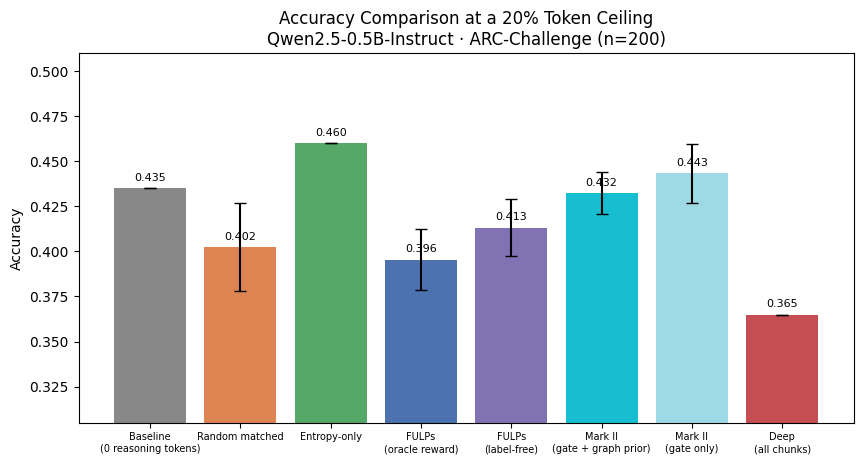

Saved: FULPs_LLM_V3_mk2/figures/fig01_accuracy_comparison.png


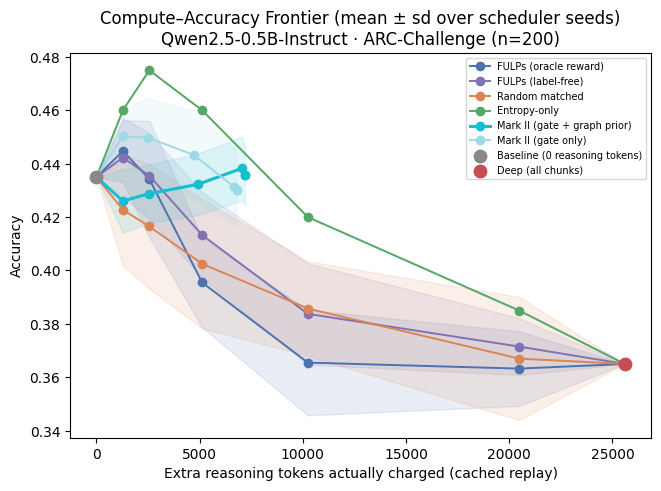

Saved: FULPs_LLM_V3_mk2/figures/fig02_compute_accuracy_frontier.png


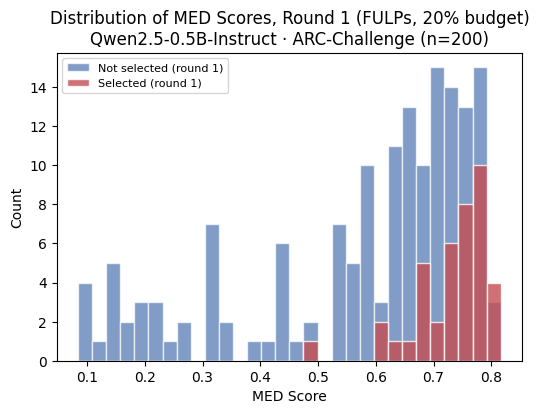

Saved: FULPs_LLM_V3_mk2/figures/fig03_scheduler_allocation.png


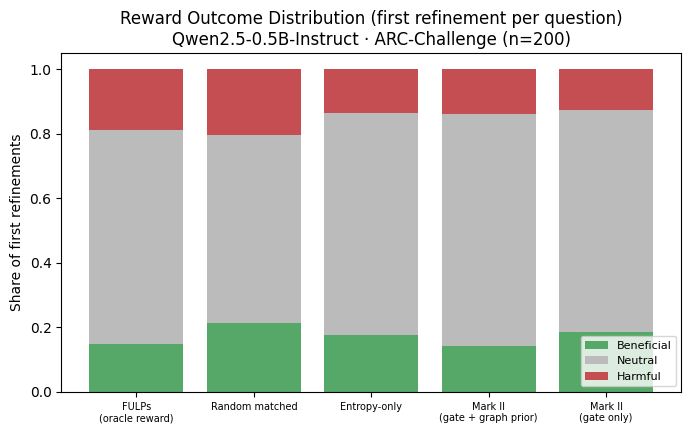

Saved: FULPs_LLM_V3_mk2/figures/fig04_reward_outcome_distribution.png


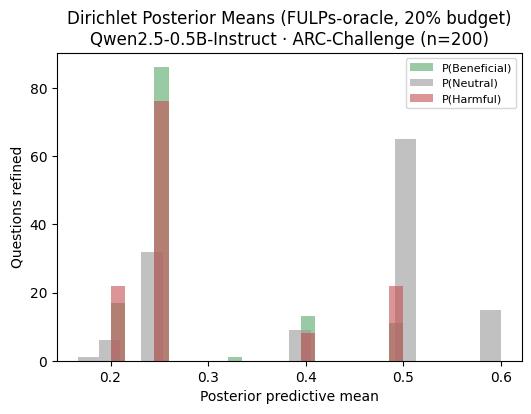

Saved: FULPs_LLM_V3_mk2/figures/fig05_dirichlet_posterior.png


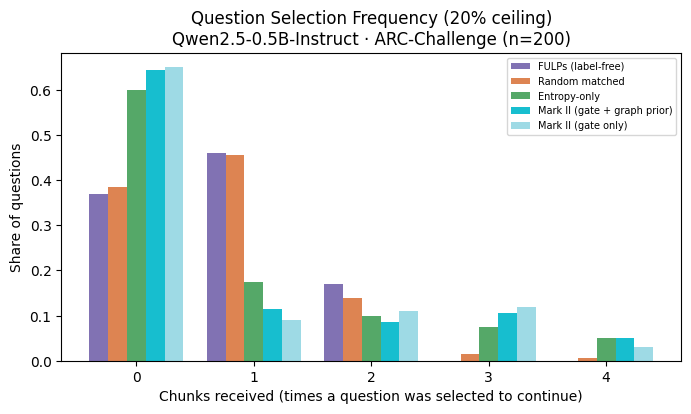

Saved: FULPs_LLM_V3_mk2/figures/fig06_question_selection_frequency.png


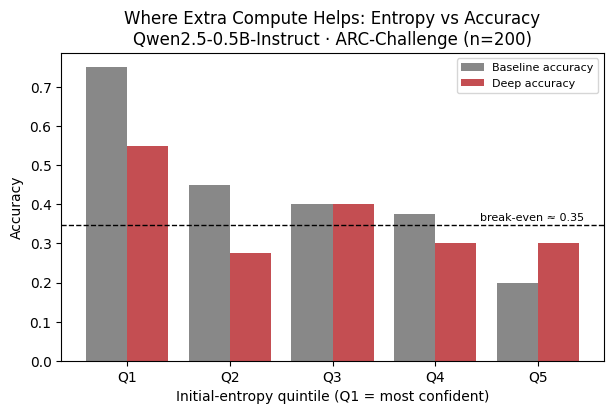

Saved: FULPs_LLM_V3_mk2/figures/fig07_entropy_accuracy_relationship.png


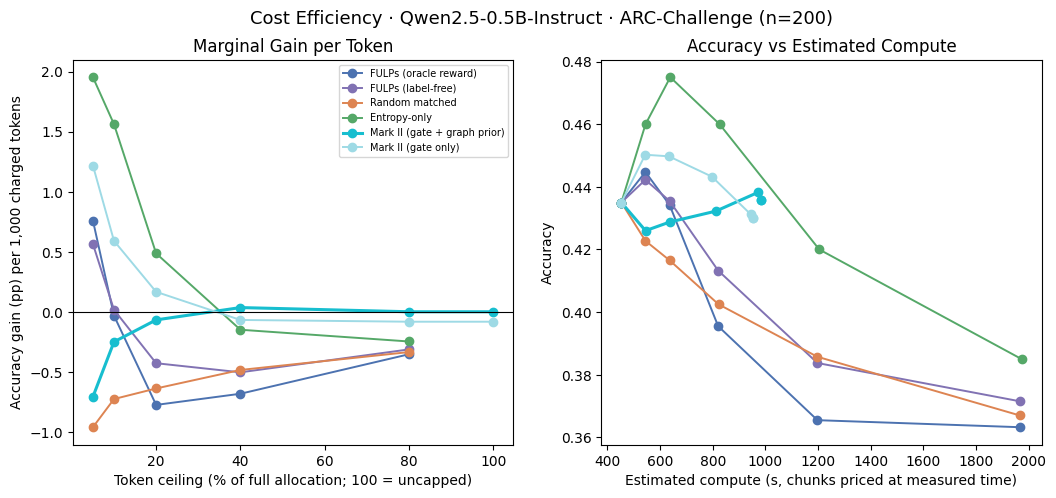

Saved: FULPs_LLM_V3_mk2/figures/fig08_cost_efficiency.png


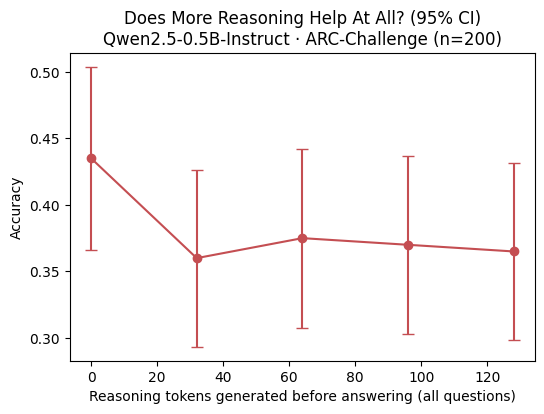

Saved: FULPs_LLM_V3_mk2/figures/fig09_accuracy_by_chunk.png


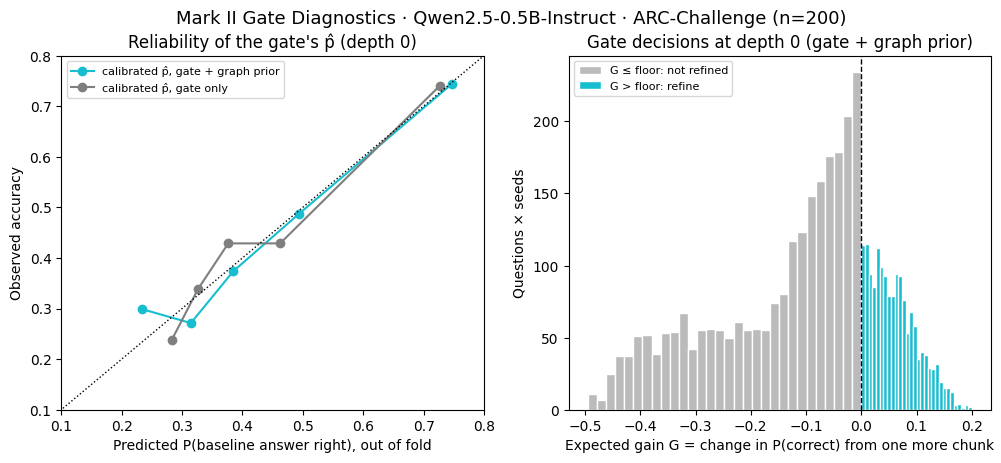

Saved: FULPs_LLM_V3_mk2/figures/fig10_gate_calibration.png


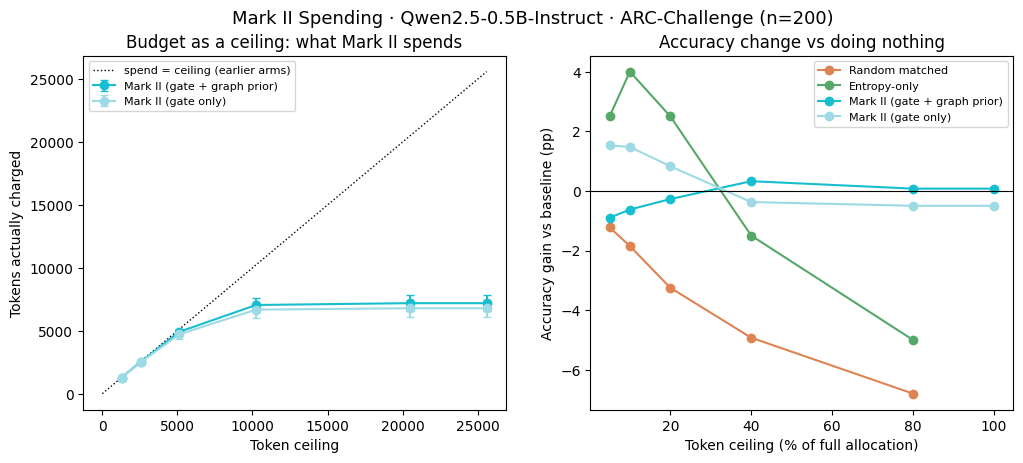

Saved: FULPs_LLM_V3_mk2/figures/fig11_budget_spend.png


In [18]:
FIG_DIR = os.path.join(CFG.OUT_DIR, "figures")
TAG = "MOCK DATA" if CFG.MODE == "mock" else f"{CFG.MODEL_NAME.split('/')[-1]} · {CFG.SUBSET} (n={N})"
GP = {True: "gate + graph prior", False: "gate only"}
COLORS = dict(baseline="#888888", fulps_oracle="#4C72B0", fulps_labelfree="#8172B3", random="#DD8452", entropy="#55A868",
              deep="#C44E52", mk2="#17BECF", mk2_alt="#9EDAE5")
LABELS = dict(baseline="Baseline (0 reasoning tokens)", fulps_oracle="FULPs (oracle reward)", fulps_labelfree="FULPs (label-free)",
              random="Random matched", entropy="Entropy-only", deep="Deep (all chunks)",
              mk2=f"Mark II ({GP[CFG.USE_GRAPH_PRIOR]})", mk2_alt=f"Mark II ({GP[not CFG.USE_GRAPH_PRIOR]})")
FIG_PATHS = []


def save_fig(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show(); plt.close(fig)
    FIG_PATHS.append(path); print("Saved:", path)


def acc_ms(arm, level):
    if arm == "baseline": return BASE_ACC, 0.0
    if arm == "deep":     return DEEP_ACC, 0.0
    v = RES[(RES.arm == arm) & (RES.level == level)].accuracy.values
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)


def fig01_accuracy_comparison():
    arms = ["baseline", "random", "entropy", "fulps_oracle", "fulps_labelfree"] + MK2_ARMS + ["deep"]
    ms = [acc_ms(a, LV) for a in arms]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.bar(range(len(arms)), [m for m, _ in ms], yerr=[s for _, s in ms], capsize=4, color=[COLORS[a] for a in arms])
    for i, (m, _) in enumerate(ms): ax.text(i, m + 0.004, f"{m:.3f}", ha="center", fontsize=8)
    lo = max(0, min(m for m, _ in ms) - 0.06); ax.set_ylim(lo, min(1, max(m for m, _ in ms) + 0.05))
    ax.set_xticks(range(len(arms))); ax.set_xticklabels([LABELS[a].replace(" (", "\n(") for a in arms], fontsize=7)
    ax.set_ylabel("Accuracy"); ax.set_title(f"Accuracy Comparison at a {int(LV*100)}% Token Ceiling\n{TAG}")
    save_fig(fig, "fig01_accuracy_comparison.png")


def fig02_compute_accuracy_frontier():
    fig, ax = plt.subplots(figsize=(7.5, 5)); full = N * N_CHUNKS * CHUNK_TOKENS
    for arm in ARMS:
        d = RES[RES.arm == arm].groupby("level").agg(x=("charged_tokens", "mean"), m=("accuracy", "mean"), s=("accuracy", "std")).reset_index()
        x, m, s = np.r_[0, d.x.values], np.r_[BASE_ACC, d.m.values], np.r_[0, d.s.fillna(0).values]
        if arm in BASE_ARMS: x, m, s = np.r_[x, full], np.r_[m, DEEP_ACC], np.r_[s, 0]
        ax.plot(x, m, marker="o", color=COLORS[arm], label=LABELS[arm], lw=2.2 if arm == "mk2" else 1.4)
        ax.fill_between(x, m - s, m + s, color=COLORS[arm], alpha=0.12)
    ax.scatter([0], [BASE_ACC], color=COLORS["baseline"], s=80, zorder=5, label=LABELS["baseline"])
    ax.scatter([full], [DEEP_ACC], color=COLORS["deep"], s=80, zorder=5, label=LABELS["deep"])
    ax.set_xlabel("Extra reasoning tokens actually charged (cached replay)"); ax.set_ylabel("Accuracy")
    ax.set_title(f"Compute–Accuracy Frontier (mean ± sd over scheduler seeds)\n{TAG}"); ax.legend(fontsize=7)
    save_fig(fig, "fig02_compute_accuracy_frontier.png")


def fig03_scheduler_allocation():
    a = ARR[("fulps_oracle", LV, 0)]; med, sel = a["med0"], a["sel0"]
    mask = np.zeros(N, bool); mask[sel] = True
    fig, ax = plt.subplots(figsize=(6, 4)); bins = np.linspace(med.min(), med.max(), 31)
    ax.hist(med[~mask], bins=bins, color="#4C72B0", edgecolor="white", alpha=0.7, label="Not selected (round 1)")
    ax.hist(med[mask], bins=bins, color="#C44E52", edgecolor="white", alpha=0.8, label="Selected (round 1)")
    ax.set_xlabel("MED Score"); ax.set_ylabel("Count"); ax.legend(fontsize=8)
    ax.set_title(f"Distribution of MED Scores, Round 1 (FULPs, {int(LV*100)}% budget)\n{TAG}")
    save_fig(fig, "fig03_scheduler_allocation.png")


def fig04_reward_outcome_distribution():
    arms = ["fulps_oracle", "random", "entropy"] + MK2_ARMS
    fig, ax = plt.subplots(figsize=(8, 4.4)); bottom = np.zeros(len(arms)); shares = []
    for a in arms:
        fc_ = ARR[(a, LV, 0)]["first_cat"]; fc_ = fc_[fc_ >= 0]; shares.append([np.mean(fc_ == c) if len(fc_) else 0 for c in (BEN, NEU, HARM)])
    shares = np.array(shares)
    for c, (name, col) in enumerate([("Beneficial", "#55A868"), ("Neutral", "#BBBBBB"), ("Harmful", "#C44E52")]):
        ax.bar(range(len(arms)), shares[:, c], bottom=bottom, color=col, label=name); bottom += shares[:, c]
    ax.set_xticks(range(len(arms))); ax.set_xticklabels([LABELS[a].replace(" (", "\n(") for a in arms], fontsize=7)
    ax.set_ylabel("Share of first refinements"); ax.legend(fontsize=8, loc="lower right")
    ax.set_title(f"Reward Outcome Distribution (first refinement per question)\n{TAG}")
    save_fig(fig, "fig04_reward_outcome_distribution.png")


def fig05_dirichlet_posterior():
    pm = ARR[("fulps_oracle", LV, 0)]["post_mean"]; seen = ARR[("fulps_oracle", LV, 0)]["done"] > 0
    fig, ax = plt.subplots(figsize=(6, 4))
    for c, (name, col) in enumerate([("P(Beneficial)", "#55A868"), ("P(Neutral)", "#999999"), ("P(Harmful)", "#C44E52")]):
        ax.hist(pm[seen, c], bins=20, alpha=0.6, color=col, label=name)
    ax.set_xlabel("Posterior predictive mean"); ax.set_ylabel("Questions refined")
    ax.set_title(f"Dirichlet Posterior Means (FULPs-oracle, {int(LV*100)}% budget)\n{TAG}"); ax.legend(fontsize=8)
    save_fig(fig, "fig05_dirichlet_posterior.png")


def fig06_question_selection_frequency():
    arms = ["fulps_labelfree", "random", "entropy"] + MK2_ARMS; w = 0.8 / len(arms)
    fig, ax = plt.subplots(figsize=(8, 4))
    for j, a in enumerate(arms):
        dn = ARR[(a, LV, 0)]["done"]
        ax.bar(np.arange(N_CHUNKS + 1) + (j - (len(arms) - 1) / 2) * w, [np.mean(dn == k) for k in range(N_CHUNKS + 1)], w, color=COLORS[a], label=LABELS[a])
    ax.set_xlabel("Chunks received (times a question was selected to continue)"); ax.set_ylabel("Share of questions")
    ax.set_title(f"Question Selection Frequency ({int(LV*100)}% ceiling)\n{TAG}"); ax.legend(fontsize=7)
    save_fig(fig, "fig06_question_selection_frequency.png")


def fig07_entropy_accuracy_relationship():
    q = np.quantile(H[:, 0], np.linspace(0, 1, 6)); b = np.clip(np.searchsorted(q, H[:, 0], side="right") - 1, 0, 4)
    fig, ax = plt.subplots(figsize=(7, 4)); x = np.arange(5)
    ax.bar(x - 0.2, [CORRECT[b == i, 0].mean() for i in range(5)], 0.4, color=COLORS["baseline"], label="Baseline accuracy")
    ax.bar(x + 0.2, [CORRECT[b == i, -1].mean() for i in range(5)], 0.4, color=COLORS["deep"], label="Deep accuracy")
    ps = np.mean([m[0].p_star for rep in range(CFG.N_SCHED_SEEDS) for _, m in fold_models(rep, CFG.USE_GRAPH_PRIOR)])
    ax.axhline(ps, color="k", ls="--", lw=1); ax.text(4.45, ps + 0.012, f"break-even ≈ {ps:.2f}", fontsize=8, ha="right")
    ax.set_xticks(x); ax.set_xticklabels([f"Q{i+1}" for i in range(5)])
    ax.set_xlabel("Initial-entropy quintile (Q1 = most confident)"); ax.set_ylabel("Accuracy"); ax.legend(fontsize=8)
    ax.set_title(f"Where Extra Compute Helps: Entropy vs Accuracy\n{TAG}")
    save_fig(fig, "fig07_entropy_accuracy_relationship.png")


def fig08_cost_efficiency():
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
    for arm in ARMS:
        d = RES[RES.arm == arm].groupby("level").agg(g=("gain_pp_per_1k_tokens", "mean"), e=("est_compute_s", "mean"), a=("accuracy", "mean")).reset_index()
        axes[0].plot(d.level * 100, d.g, marker="o", color=COLORS[arm], label=LABELS[arm], lw=2.2 if arm == "mk2" else 1.4)
        axes[1].plot(np.r_[TIMEC[:, 0].sum(), d.e], np.r_[BASE_ACC, d.a], marker="o", color=COLORS[arm], label=LABELS[arm], lw=2.2 if arm == "mk2" else 1.4)
    axes[0].axhline(0, color="k", lw=0.8)
    axes[0].set_xlabel("Token ceiling (% of full allocation; 100 = uncapped)"); axes[0].set_ylabel("Accuracy gain (pp) per 1,000 charged tokens"); axes[0].set_title("Marginal Gain per Token")
    axes[1].set_xlabel("Estimated compute (s, chunks priced at measured time)"); axes[1].set_ylabel("Accuracy"); axes[1].set_title("Accuracy vs Estimated Compute")
    axes[0].legend(fontsize=7); fig.suptitle(f"Cost Efficiency · {TAG}", fontsize=13)
    save_fig(fig, "fig08_cost_efficiency.png")


def fig09_accuracy_by_chunk():
    acc = CORRECT.mean(0); se = np.sqrt(acc * (1 - acc) / N)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.errorbar(np.arange(N_STATES) * CHUNK_TOKENS, acc, yerr=1.96 * se, marker="o", capsize=4, color=COLORS["deep"])
    ax.set_xlabel("Reasoning tokens generated before answering (all questions)"); ax.set_ylabel("Accuracy")
    ax.set_title(f"Does More Reasoning Help At All? (95% CI)\n{TAG}")
    save_fig(fig, "fig09_accuracy_by_chunk.png")


def fig10_gate_calibration():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    for flag, col in ((True, COLORS["mk2"]), (False, "#7F7F7F")):
        p = np.concatenate([oof_gate_stats(rep, flag)[0] for rep in range(CFG.N_SCHED_SEEDS)]); y = np.tile(CORRECT[:, 0], CFG.N_SCHED_SEEDS)
        qs = np.quantile(p, np.linspace(0, 1, 6)); b = np.clip(np.searchsorted(qs, p, side="right") - 1, 0, 4)
        axes[0].plot([p[b == i].mean() for i in range(5)], [y[b == i].mean() for i in range(5)], marker="o", color=col, label=f"calibrated p̂, {GP[flag]}")
    axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set_xlim(0.1, 0.8); axes[0].set_ylim(0.1, 0.8)
    axes[0].set_xlabel("Predicted P(baseline answer right), out of fold"); axes[0].set_ylabel("Observed accuracy"); axes[0].legend(fontsize=8); axes[0].set_title("Reliability of the gate's p̂ (depth 0)")
    g0 = np.concatenate([oof_gate_stats(rep, CFG.USE_GRAPH_PRIOR)[1] for rep in range(CFG.N_SCHED_SEEDS)])
    axes[1].hist(g0[g0 <= CFG.GAIN_FLOOR], bins=30, color="#BBBBBB", edgecolor="white", label="G ≤ floor: not refined")
    axes[1].hist(g0[g0 > CFG.GAIN_FLOOR], bins=30, color=COLORS["mk2"], edgecolor="white", label="G > floor: refine")
    axes[1].axvline(CFG.GAIN_FLOOR, color="k", ls="--", lw=1); axes[1].set_xlabel("Expected gain G = change in P(correct) from one more chunk"); axes[1].set_ylabel("Questions × seeds")
    axes[1].legend(fontsize=8); axes[1].set_title(f"Gate decisions at depth 0 ({GP[CFG.USE_GRAPH_PRIOR]})")
    fig.suptitle(f"Mark II Gate Diagnostics · {TAG}", fontsize=13); save_fig(fig, "fig10_gate_calibration.png")


def fig11_budget_spend():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6)); lv = list(CFG.BUDGET_LEVELS) + [1.0]
    full = N * N_CHUNKS * CHUNK_TOKENS
    axes[0].plot([0, full], [0, full], "k:", lw=1, label="spend = ceiling (earlier arms)")
    for arm in MK2_ARMS:
        d = RES[RES.arm == arm].groupby("level").charged_tokens.agg(["mean", "std"]).reindex(lv)
        axes[0].errorbar([l * full for l in lv], d["mean"], yerr=d["std"].fillna(0), marker="o", color=COLORS[arm], label=LABELS[arm], capsize=3)
    axes[0].set_xlabel("Token ceiling"); axes[0].set_ylabel("Tokens actually charged"); axes[0].set_title("Budget as a ceiling: what Mark II spends"); axes[0].legend(fontsize=8)
    for arm in ["random", "entropy"] + MK2_ARMS:
        d = RES[RES.arm == arm].groupby("level").acc_gain_pp.mean().reindex(lv)
        axes[1].plot([l * 100 for l in lv], d.values, marker="o", color=COLORS[arm], label=LABELS[arm])
    axes[1].axhline(0, color="k", lw=0.8); axes[1].set_xlabel("Token ceiling (% of full allocation)"); axes[1].set_ylabel("Accuracy gain vs baseline (pp)")
    axes[1].set_title("Accuracy change vs doing nothing"); axes[1].legend(fontsize=8)
    fig.suptitle(f"Mark II Spending · {TAG}", fontsize=13); save_fig(fig, "fig11_budget_spend.png")


for f in (fig01_accuracy_comparison, fig02_compute_accuracy_frontier, fig03_scheduler_allocation,
          fig04_reward_outcome_distribution, fig05_dirichlet_posterior, fig06_question_selection_frequency,
          fig07_entropy_accuracy_relationship, fig08_cost_efficiency, fig09_accuracy_by_chunk,
          fig10_gate_calibration, fig11_budget_spend):
    f()

## 11. Compute accounting and reproducibility record

In [19]:
sched = RES[RES.arm.isin(ARMS)]
mk_fit = np.mean(list(FIT_SECONDS.values())) if FIT_SECONDS else 0.0
unc = RES[(RES.arm == "mk2") & (RES.level == 1.0)]
ACCOUNTING = {
    "1. Live inference": "not run here; re-uses the token notebook's cache (measured seconds below come from that run)",
    "   total measured generation+probe time in the cache (s)": round(float(TIME.sum()), 1),
    "2. Tokens: baseline / full extra charged / actually generated (deep)": f"0 / {N * N_CHUNKS * CHUNK_TOKENS} / {int(TOK.sum())}",
    "   Mark II uncapped: tokens charged (mean) / share of full allocation": f"{unc.charged_tokens.mean():.0f} / {unc.spend_share.mean():.3f}",
    "3. Cached replay, all runs (s)": round(REPLAY_S, 2),
    "4. Estimated compute, baseline / deep (s)": f"{TIMEC[:, 0].sum():.1f} / {TIMEC[:, -1].sum():.1f}",
    "   estimated compute, Mark II uncapped (s)": round(float(unc.est_compute_s.mean()), 1),
    "5. Scheduler decision overhead per run: FULPs / random / entropy / Mark II (s)": " / ".join(
        f"{sched[sched.arm.isin(s_)].overhead_s.mean():.5f}" for s_ in (FULPS_ARMS, {"random"}, {"entropy"}, {"mk2"})),
    "   Mark II calibration fit per scheduler seed (s, offline, label-dependent)": round(float(mk_fit), 3),
    "6. Graph construction (s)": round(GRAPH["seconds"], 4),
    "7. End-to-end notebook runtime so far (s)": round(time.perf_counter() - T_NOTEBOOK_START, 1),
}
for k, v in ACCOUNTING.items(): print(f"{k:78s} {v}")

# ---- reproducibility artifacts ----
cfg_dump = asdict(CFG); cfg_dump.update(scheduler_seeds=list(range(CFG.N_SCHED_SEEDS)), sample_ids=[str(i) for i in CACHE["ids"]], torch=torch.__version__,
                                         n_chunks=N_CHUNKS, chunk_tokens=CHUNK_TOKENS, fold_seed_base=10_000)
json.dump(cfg_dump, open(os.path.join(CFG.OUT_DIR, "config_and_reproducibility.json"), "w"), indent=1, default=str)

p0, g0 = oof_gate_stats(0, CFG.USE_GRAPH_PRIOR)
QTAB = pd.DataFrame(dict(id=[str(i) for i in CACHE["ids"]], gold=GOLD, base_pred=P[:, 0].argmax(-1), base_correct=CORRECT[:, 0],
                         deep_correct=CORRECT[:, -1], entropy0=H[:, 0], attention_A=ATT.numpy(), degree=GRAPH["deg_out"],
                         mk2_p_hat_oof=p0, mk2_gain_oof=g0))
for arm in ARMS:
    QTAB[f"{arm}_refinements"] = ARR[(arm, LV, 0)]["done"]; QTAB[f"{arm}_final_correct"] = ARR[(arm, LV, 0)]["final_correct"]
QTAB.to_csv(os.path.join(CFG.OUT_DIR, "question_level_results.csv"), index=False)
print("\nFigures:"); [print("  ", p) for p in FIG_PATHS]
print("Outputs in:", os.path.abspath(CFG.OUT_DIR))

1. Live inference                                                              not run here; re-uses the token notebook's cache (measured seconds below come from that run)
   total measured generation+probe time in the cache (s)                       2360.5
2. Tokens: baseline / full extra charged / actually generated (deep)           0 / 25600 / 25123
   Mark II uncapped: tokens charged (mean) / share of full allocation          7192 / 0.281
3. Cached replay, all runs (s)                                                 26.85
4. Estimated compute, baseline / deep (s)                                      452.9 / 2360.5
   estimated compute, Mark II uncapped (s)                                     983.7
5. Scheduler decision overhead per run: FULPs / random / entropy / Mark II (s) 0.00335 / 0.00035 / 0.00013 / 0.05404
   Mark II calibration fit per scheduler seed (s, offline, label-dependent)    0.283
6. Graph construction (s)                                                      0.185
7.

## 12. Limitations (read before quoting any result)

- **The design was informed by these same 200 questions.** Every label-dependent quantity is cross-fitted, but the *choice* of a break-even gate, depth-specific parameters and features came from looking at this data. Treat results here as exploratory; confirm on a fresh sample.
- **One model, one benchmark, one sample (n=200).** Differences of a few points are within noise; read the CIs, not only p-values. Scheduler seeds replay one cached generation per question and, for Mark II, vary only the fold assignment.
- **Labelled calibration set required.** α, β, the `p̂` calibration and the neighbour labels come from labelled questions that were run at every depth. A deployment needs such a set once, offline; it cannot learn from unlabeled traffic.
- **Later chunks carry little signal.** On the cache, entropy flags wrong answers well at depth 0 and barely after reasoning starts, so beyond the first chunk the gate is close to a global go/no-go. 1C-style per-question memory would not help at this sample size either.
- **2B adds little on this data** in an earlier check (neighbours' correctness predicts difficulty about as well as entropy, and adds nothing on top). Run with `USE_GRAPH_PRIOR=False` to see the difference directly.
- **Mark II may spend less than its ceiling**, so equal-ceiling comparisons are not equal-spend comparisons.
- **Chunks are charged in full** even if generation ended early; the first 32 tokens also cut reasoning mid-sentence, which biased early answers toward option A in the earlier analysis.
- **Attention is not learned** (`A_i = 1/deg`), and Mark II does not use it.
- **Dataset revision is not pinned** in the token notebook's cache.

## 13. Code-reuse audit

| Component | Status |
|---|---|
| `scheduler.py` cell (`LAMBDA`, `ALPHA`, `MED_WEIGHTS`, `compute_uncertainty`, `CostTracker`, `BudgetTracker`, `compute_beu`, `compute_med`, `laplace_smooth`, `ThompsonSampler`) | **Reused unchanged** (verbatim; used by the comparison arms and for the entropy computation) |
| `GATAttentionScorer`, kNN graph, symmetric normalization Â | **Reused unchanged**; Â is now actually used (by the 2B neighbour feature) |
| `DirichletThompsonSampler`, reward categories, FULPs / Random / Entropy-only arms, replay runner, statistics, figure style | **Unchanged from the token notebook** |
| Reward categories (Beneficial / Neutral / Harmful) | **Reused** for reporting in every arm, and as the quantity whose net value `P(B) − P(H)` the gate estimates directly |
| MED, attention term, Thompson sampling | **Not used by Mark II** (still run in the comparison arms) |
| New | cross-fitted per-depth gate (α, β, calibrated `p̂`, break-even), 2B neighbour feature and toggle, budget-as-ceiling with carry-forward, spend metrics, efficiency-notebook metric set, cross-notebook comparison, Figs. 10-11 |